## Section 1: Problem Statement & App Value Proposition
Multicomponent distillation calculations require engineers to evaluate vapor-liquid equilibrium, material balances, operating conditions, and product compositions to determine whether a desired separation can be achieved. During my chemical engineering coursework, I observed that setting up and evaluating only one distillation column can take more than 40 minutes, particularly when different operating conditions must be tested. Repeating these calculations to investigate changes in reflux ratio, feed stage, pressure, number of stages, or feed composition further increases the time required. This creates an opportunity for an interactive application that performs the calculations automatically while allowing the user to visualize how changes in operating conditions affect separation. The evidence for this problem is my own observation of the time required to set up and evaluate a distillation column during chemical engineering process simulation work (personal observation, 2026).
Value Proposition: For chemical engineering students and process engineers who need to perform preliminary evaluations of multicomponent distillation columns, my app is an interactive distillation-column calculation and visualization tool. Unlike performing repetitive calculations manually or setting up a complete process simulation for an initial evaluation, my app allows users to quickly modify feed and column operating conditions, calculate distillate and bottoms compositions and key-component purity and recovery, and visualize component separation throughout the column.


## Section 2: Project Description & Engineering Basis

This application is an interactive multicomponent distillation column simulator designed to perform preliminary separation calculations and visualize how operating conditions affect column performance. The user selects between two and eight hydrocarbon components and specifies the feed flow rate, feed temperature, feed pressure, feed composition, number of stages, feed stage, distillate flow rate, reflux ratio, column top pressure, and pressure drop. The user also identifies the light key (LK) and heavy key (HK) components.

The engineering calculations used in the application include:

Mass fraction to mole fraction conversion:

z_i = (w_i / MW_i) / Σ(w_j / MW_j)

Vapor-liquid equilibrium (VLE):

y_i = K_i x_i

Wilson correlation for equilibrium K-values:

K_i = (Pc_i / P) exp[5.373(1 + ω_i)(1 - Tc_i / T)]

Rachford-Rice equation for the feed vapor fraction:

Σ[z_i(K_i - 1) / (1 + β(K_i - 1))] = 0

Overall column material balance:

F = D + B

Component material balance:

F z_i = D x_D,i + B x_B,i

Reflux liquid flow:

L = R D

Rectifying-section vapor flow:

V = D(R + 1)

Stage pressure profile:

P_j = P_top + [(j - 1)/(N - 1)] ΔP

Bubble-point condition:

Σ(K_i x_i) = 1

The application iteratively solves the stage component balances and calculates the distillate and bottoms compositions, light-key and heavy-key purity and recovery, and material-balance error. It also generates a liquid composition profile through the column and an animated visualization of component separation. The operational goal is to allow users to quickly investigate how changes in column design and operating conditions influence multicomponent separation.

Section 3: GUI Sketch Image
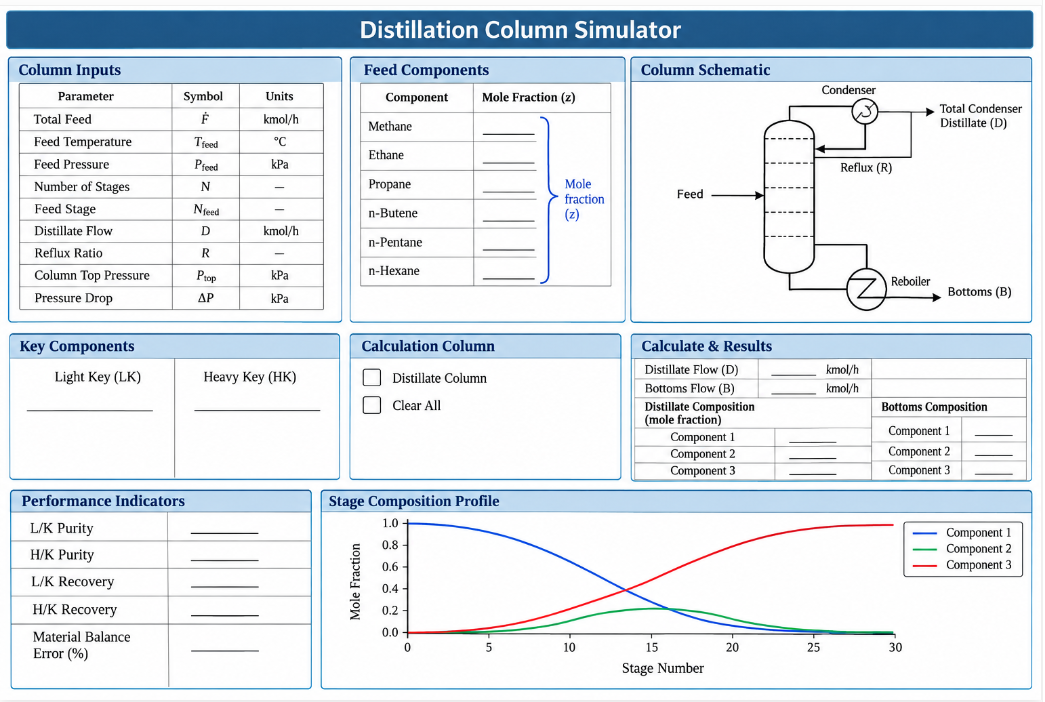

In [1]:
#Distillation Column Simulator

**AI Assistance Disclosure:** ChatGPT (OpenAI) was used to assist with brainstorming the application design, reviewing the chemical engineering equations, and providing guidance during Python code development. The final application was developed, tested, and reviewed by the student.

In [2]:
# ============================================================
# DISTILLATION COLUMN SIMULATOR
# Calculation Engine - Part 1
# ============================================================

import numpy as np
from scipy.optimize import brentq
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. COMPONENT PROPERTY DATABASE
# MW = molecular weight (lb/lbmol)
# Tc = critical temperature (K)
# Pc = critical pressure (psia)
# omega = acentric factor
# ------------------------------------------------------------

component_data = {
    "Methane": {
        "MW": 16.04,
        "Tc": 190.56,
        "Pc": 667.0,
        "omega": 0.011
    },

    "Ethylene": {
        "MW": 28.05,
        "Tc": 282.34,
        "Pc": 731.0,
        "omega": 0.087
    },

    "Ethane": {
        "MW": 30.07,
        "Tc": 305.32,
        "Pc": 708.3,
        "omega": 0.099
    },

    "Propylene": {
        "MW": 42.08,
        "Tc": 364.90,
        "Pc": 667.0,
        "omega": 0.142
    },

    "Propane": {
        "MW": 44.10,
        "Tc": 369.83,
        "Pc": 616.0,
        "omega": 0.152
    },

    "1,3-Butadiene": {
        "MW": 54.09,
        "Tc": 425.12,
        "Pc": 627.0,
        "omega": 0.191
    },

    "1-Butene": {
        "MW": 56.11,
        "Tc": 419.59,
        "Pc": 583.0,
        "omega": 0.191
    },

    "n-Butane": {
        "MW": 58.12,
        "Tc": 425.12,
        "Pc": 550.7,
        "omega": 0.200
    }
}


# ------------------------------------------------------------
# 2. WILSON K-VALUE EQUATION
#
# Ki = (Pci/P) *
#      exp[5.373(1 + omega_i)(1 - Tci/T)]
#
# T must be in Kelvin
# P and Pc must use the same pressure units
# ------------------------------------------------------------

def wilson_K(component, T, P):

    data = component_data[component]

    Tc = data["Tc"]
    Pc = data["Pc"]
    omega = data["omega"]

    K = (Pc / P) * np.exp(
        5.373 * (1 + omega) * (1 - Tc / T)
    )

    return K


# ------------------------------------------------------------
# 3. CONVERT FAHRENHEIT TO KELVIN
# ------------------------------------------------------------

def F_to_K(T_F):

    return (T_F - 32) * 5 / 9 + 273.15


# ------------------------------------------------------------
# 4. MASS FRACTION TO MOLE FRACTION
#
# zi = (wi/MWi) / sum(wj/MWj)
# ------------------------------------------------------------

def mass_to_mole_fractions(components, mass_fractions):

    mole_amounts = []

    for component, w in zip(components, mass_fractions):

        MW = component_data[component]["MW"]

        mole_amounts.append(w / MW)

    mole_amounts = np.array(mole_amounts)

    mole_fractions = mole_amounts / np.sum(mole_amounts)

    return mole_fractions


# ------------------------------------------------------------
# 5. FEED COMPONENT MOLAR FLOWS
#
# Fi = F * zi
# ------------------------------------------------------------

def component_feed_flows(F, z):

    return F * np.array(z)


# ------------------------------------------------------------
# 6. CALCULATE K-VALUES FOR ALL COMPONENTS
# ------------------------------------------------------------

def calculate_K_values(components, T, P):

    K_values = []

    for component in components:

        K_values.append(
            wilson_K(component, T, P)
        )

    return np.array(K_values)


# ------------------------------------------------------------
# 7. RACHFORD-RICE EQUATION
#
# sum[ zi(Ki - 1) /
#      (1 + beta(Ki - 1)) ] = 0
#
# beta = vapor fraction
# q = 1 - beta
# ------------------------------------------------------------

def rachford_rice(beta, z, K):

    return np.sum(
        z * (K - 1) /
        (1 + beta * (K - 1))
    )


def calculate_vapor_fraction(z, K):

    f0 = rachford_rice(0.0, z, K)
    f1 = rachford_rice(1.0, z, K)

    # Entire feed is vapor
    if f0 > 0 and f1 > 0:
        return 1.0

    # Entire feed is liquid
    if f0 < 0 and f1 < 0:
        return 0.0

    # Two-phase feed
    beta = brentq(
        rachford_rice,
        0.0,
        1.0,
        args=(z, K)
    )

    return beta


# ------------------------------------------------------------
# 8. PRESSURE PROFILE THROUGH COLUMN
#
# Pj = Ptop +
#      ((j - 1)/(N - 1))*deltaP
# ------------------------------------------------------------

def pressure_profile(P_top, delta_P, N):

    return np.linspace(
        P_top,
        P_top + delta_P,
        N
    )


# ------------------------------------------------------------
# 9. OVERALL COLUMN MATERIAL BALANCE
#
# F = D + B
# B = F - D
# ------------------------------------------------------------

def column_balance(F, D):

    B = F - D

    return B


# ------------------------------------------------------------
# 10. REFLUX FLOW
#
# R = L/D
# L = R*D
# ------------------------------------------------------------

def reflux_flow(R, D):

    L = R * D

    return L


# ------------------------------------------------------------
# 11. TOTAL CONDENSER VAPOR FLOW
#
# V = D + L
# V = D(R + 1)
# ------------------------------------------------------------

def condenser_vapor_flow(D, R):

    V = D * (R + 1)

    return V


# ------------------------------------------------------------
# 12. FEED LIQUID AND VAPOR PORTIONS
#
# q = liquid fraction
#
# Liquid portion = qF
# Vapor portion = (1-q)F
# ------------------------------------------------------------

def feed_phase_flows(F, beta):

    q = 1 - beta

    F_liquid = q * F
    F_vapor = beta * F

    return q, F_liquid, F_vapor


# ------------------------------------------------------------
# 13. STAGE EQUILIBRIUM
#
# yi = Ki*xi / sum(Ki*xi)
# ------------------------------------------------------------

def equilibrium_y(x, K):

    y = K * x

    y = y / np.sum(y)

    return y


# ------------------------------------------------------------
# 14. COLUMN INPUT CHECKS
# ------------------------------------------------------------

def check_inputs(F, D, N, feed_stage, fractions):

    if F <= 0:
        raise ValueError("Feed flow must be greater than zero.")

    if D <= 0 or D >= F:
        raise ValueError(
            "Distillate flow must be greater than 0 and less than feed flow."
        )

    if N < 2 or N > 50:
        raise ValueError(
            "Number of stages must be between 2 and 50."
        )

    if feed_stage < 1 or feed_stage > N:
        raise ValueError(
            "Feed stage must be between 1 and the selected number of stages."
        )

    if not np.isclose(np.sum(fractions), 1.0, atol=0.001):
        raise ValueError(
            "Component fractions must add to 1.000."
        )


print("Distillation Column Simulator calculation engine loaded.")

Distillation Column Simulator calculation engine loaded.


In [2]:
# ============================================================
# TEST FEED
# ============================================================

# Select components
components = [
    "Ethylene",
    "Ethane",
    "Propylene",
    "Propane"
]

# Feed mass fractions
mass_fractions = np.array([
    0.44,   # Ethylene
    0.36,   # Ethane
    0.15,   # Propylene
    0.05    # Propane
])

# Operating conditions
F = 1000.0          # lbmol/hr
T_feed_F = 100.0    # degrees F
P_feed = 392.0      # psia

N = 40              # number of stages
feed_stage = 18
D = 850.0           # lbmol/hr
R = 1.16            # reflux ratio

P_top = 392.0       # psia
delta_P = 7.25      # psi


# ------------------------------------------------------------
# CHECK INPUTS
# ------------------------------------------------------------

check_inputs(
    F,
    D,
    N,
    feed_stage,
    mass_fractions
)


# ------------------------------------------------------------
# CONVERT MASS FRACTIONS TO MOLE FRACTIONS
# ------------------------------------------------------------

z = mass_to_mole_fractions(
    components,
    mass_fractions
)


# ------------------------------------------------------------
# FEED TEMPERATURE
# ------------------------------------------------------------

T_feed_K = F_to_K(T_feed_F)


# ------------------------------------------------------------
# CALCULATE K-VALUES
# ------------------------------------------------------------

K = calculate_K_values(
    components,
    T_feed_K,
    P_feed
)


# ------------------------------------------------------------
# FEED VAPOR FRACTION AND q
# ------------------------------------------------------------

beta = calculate_vapor_fraction(z, K)

q, F_liquid, F_vapor = feed_phase_flows(
    F,
    beta
)


# ------------------------------------------------------------
# COLUMN FLOWS
# ------------------------------------------------------------

B = column_balance(F, D)

L = reflux_flow(R, D)

V = condenser_vapor_flow(D, R)

pressures = pressure_profile(
    P_top,
    delta_P,
    N
)


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("========== FEED CALCULATION ==========")

print("\nComponent        Mole Fraction       K-value")

for component, zi, Ki in zip(components, z, K):
    print(f"{component:<15} {zi:>10.4f}        {Ki:>10.4f}")

print("\nFeed vapor fraction =", round(beta, 4))
print("Feed liquid fraction q =", round(q, 4))

print("\nFeed vapor flow =", round(F_vapor, 2), "lbmol/hr")
print("Feed liquid flow =", round(F_liquid, 2), "lbmol/hr")

print("\n========== COLUMN ==========")

print("Number of stages =", N)
print("Feed stage =", feed_stage)

print("\nFeed =", F, "lbmol/hr")
print("Distillate =", D, "lbmol/hr")
print("Bottoms =", B, "lbmol/hr")

print("\nReflux flow =", round(L, 2), "lbmol/hr")
print("Condenser vapor flow =", round(V, 2), "lbmol/hr")

print("\nTop pressure =", round(pressures[0], 2), "psia")
print("Bottom pressure =", round(pressures[-1], 2), "psia")

========== FEED CALCULATION ==========

Component        Mole Fraction       K-value
Ethylene            0.4848            3.1904
Ethane              0.3700            2.0099
Propylene           0.1102            0.5865
Propane             0.0350            0.4865

Feed vapor fraction = 1.0
Feed liquid fraction q = 0.0

Feed vapor flow = 1000.0 lbmol/hr
Feed liquid flow = 0.0 lbmol/hr

========== COLUMN ==========
Number of stages = 40
Feed stage = 18

Feed = 1000.0 lbmol/hr
Distillate = 850.0 lbmol/hr
Bottoms = 150.0 lbmol/hr

Reflux flow = 986.0 lbmol/hr
Condenser vapor flow = 1836.0 lbmol/hr

Top pressure = 392.0 psia
Bottom pressure = 399.25 psia


In [3]:
# ============================================================
# COLUMN STAGE MODEL - PART 2
# ============================================================

# ------------------------------------------------------------
# 1. INTERNAL LIQUID AND VAPOR FLOWS
#
# Above the feed:
# L = R*D
# V = L + D
#
# Below the feed:
# L_bar = L + qF
# V_bar = V - (1-q)F
# ------------------------------------------------------------

L_rect = R * D
V_rect = L_rect + D

L_strip = L_rect + q * F
V_strip = V_rect - (1 - q) * F


print("========== INTERNAL COLUMN FLOWS ==========")

print("\nRectifying section:")
print("Liquid flow =", round(L_rect, 2), "lbmol/hr")
print("Vapor flow  =", round(V_rect, 2), "lbmol/hr")

print("\nStripping section:")
print("Liquid flow =", round(L_strip, 2), "lbmol/hr")
print("Vapor flow  =", round(V_strip, 2), "lbmol/hr")


# ------------------------------------------------------------
# 2. CHECK FEED-STAGE TOTAL BALANCE
#
# L_rect + V_strip + F
# =
# L_strip + V_rect
# ------------------------------------------------------------

feed_stage_in = L_rect + V_strip + F
feed_stage_out = L_strip + V_rect

print("\n========== FEED STAGE BALANCE ==========")

print("Flow entering feed stage =",
      round(feed_stage_in, 2),
      "lbmol/hr")

print("Flow leaving feed stage  =",
      round(feed_stage_out, 2),
      "lbmol/hr")

print("Balance error =",
      round(feed_stage_in - feed_stage_out, 8),
      "lbmol/hr")


# ------------------------------------------------------------
# 3. CREATE ARRAYS FOR ALL ACTIVE STAGES
#
# x[j,i] = liquid mole fraction of component i on stage j
# y[j,i] = vapor mole fraction of component i on stage j
# ------------------------------------------------------------

n_components = len(components)

x_stage = np.zeros((N, n_components))
y_stage = np.zeros((N, n_components))

print("\n========== STAGE ARRAYS ==========")
print("Active stages =", N)
print("Components =", n_components)
print("Liquid composition array shape =", x_stage.shape)
print("Vapor composition array shape =", y_stage.shape)


# ------------------------------------------------------------
# 4. INITIAL COMPOSITION GUESS
#
# Start every stage with the feed composition.
# The numerical solver will later update these values.
# ------------------------------------------------------------

for j in range(N):

    x_stage[j, :] = z

    K_stage = calculate_K_values(
        components,
        T_feed_K,
        pressures[j]
    )

    y_stage[j, :] = equilibrium_y(
        x_stage[j, :],
        K_stage
    )


# ------------------------------------------------------------
# 5. DISPLAY INITIAL EQUILIBRIUM EXAMPLE
# ------------------------------------------------------------

print("\n========== INITIAL STAGE EXAMPLE ==========")

print("\nStage 1:")
print("Component        Liquid x        Vapor y")

for i, component in enumerate(components):

    print(
        f"{component:<15}"
        f"{x_stage[0,i]:>10.4f}"
        f"{y_stage[0,i]:>15.4f}"
    )


# ------------------------------------------------------------
# 6. CHECK COMPOSITION SUMS
# ------------------------------------------------------------

print("\nLiquid mole fraction sum =",
      round(np.sum(x_stage[0, :]), 6))

print("Vapor mole fraction sum =",
      round(np.sum(y_stage[0, :]), 6))

========== INTERNAL COLUMN FLOWS ==========

Rectifying section:
Liquid flow = 986.0 lbmol/hr
Vapor flow  = 1836.0 lbmol/hr

Stripping section:
Liquid flow = 986.0 lbmol/hr
Vapor flow  = 836.0 lbmol/hr

========== FEED STAGE BALANCE ==========
Flow entering feed stage = 2822.0 lbmol/hr
Flow leaving feed stage  = 2822.0 lbmol/hr
Balance error = 0.0 lbmol/hr

========== STAGE ARRAYS ==========
Active stages = 40
Components = 4
Liquid composition array shape = (40, 4)
Vapor composition array shape = (40, 4)

========== INITIAL STAGE EXAMPLE ==========

Stage 1:
Component        Liquid x        Vapor y
Ethylene           0.4848         0.6521
Ethane             0.3700         0.3135
Propylene          0.1102         0.0272
Propane            0.0350         0.0072

Liquid mole fraction sum = 1.0
Vapor mole fraction sum = 1.0


In [5]:
# ============================================================
# COLUMN STAGE MODEL - PART 3
# Stage Temperatures and Equilibrium
# ============================================================

In [6]:
print("Cell 6 is running")

Cell 6 is running


In [5]:
# ============================================================
# STAGE EQUILIBRIUM CALCULATIONS
# ============================================================

# Bubble-point equation:
# sum(Ki * xi) = 1

def bubble_residual(T, x, P, components):

    K = calculate_K_values(
        components,
        T,
        P
    )

    return np.sum(K * x) - 1.0


# Calculate the equilibrium temperature of one stage

def stage_temperature(x, P, components):

    T = brentq(
        bubble_residual,
        150.0,
        600.0,
        args=(x, P, components)
    )

    return T


print("Stage temperature functions loaded.")

Stage temperature functions loaded.


In [15]:
# ============================================================
# STAGE EQUILIBRIUM
# ============================================================

def stage_equilibrium(x, T, P, components):

    K = calculate_K_values(
        components,
        T,
        P
    )

    # Equilibrium relationship
    y = K * x

    return y, K


print("Stage equilibrium function loaded.")

Stage equilibrium function loaded.


In [9]:
# ============================================================
# CALCULATE EQUILIBRIUM FOR ALL ACTIVE STAGES
# ============================================================

T_stage = np.zeros(N)

K_stage_all = np.zeros(
    (N, n_components)
)

for j in range(N):

    # Calculate equilibrium temperature
    T_stage[j] = stage_temperature(
        x_stage[j, :],
        pressures[j],
        components
    )

    # Calculate K-values and vapor composition
    y_stage[j, :], K_stage_all[j, :] = stage_equilibrium(
        x_stage[j, :],
        T_stage[j],
        pressures[j],
        components
    )


print("Equilibrium calculated for all", N, "stages.")

Equilibrium calculated for all 40 stages.


In [10]:
# ============================================================
# CHECK STAGE 1 EQUILIBRIUM RESULTS
# ============================================================

T_stage1_F = (T_stage[0] - 273.15) * 9 / 5 + 32

print("========== STAGE 1 EQUILIBRIUM ==========")

print("\nStage 1 temperature =",
      round(T_stage1_F, 2), "°F")

print("Stage 1 pressure =",
      round(pressures[0], 2), "psia")

print("\nComponent        Liquid x      K-value      Vapor y")

for i, component in enumerate(components):

    print(
        f"{component:<15}"
        f"{x_stage[0,i]:>10.4f}"
        f"{K_stage_all[0,i]:>13.4f}"
        f"{y_stage[0,i]:>13.4f}"
    )

print("\nLiquid mole fraction sum =",
      round(np.sum(x_stage[0, :]), 6))

print("Vapor mole fraction sum =",
      round(np.sum(y_stage[0, :]), 6))

print("Equilibrium residual =",
      round(np.sum(K_stage_all[0, :] *
                   x_stage[0, :]) - 1.0, 10))

========== STAGE 1 EQUILIBRIUM ==========

Stage 1 temperature = 24.2 °F
Stage 1 pressure = 392.0 psia

Component        Liquid x      K-value      Vapor y
Ethylene           0.4848       1.3900       0.6739
Ethane             0.3700       0.8104       0.2998
Propylene          0.1102       0.1898       0.0209
Propane            0.0350       0.1535       0.0054

Liquid mole fraction sum = 1.0
Vapor mole fraction sum = 1.0
Equilibrium residual = 0.0


In [13]:
# Check Stage 1 results

T_stage1_F = (T_stage[0] - 273.15) * 9/5 + 32

print("Stage 1 temperature:", round(T_stage1_F, 2), "F")
print("Stage 1 pressure:", round(pressures[0], 2), "psia")

print("\nComponent      Liquid x      K-value      Vapor y")

for i, component in enumerate(components):
    print(
        f"{component:<15}"
        f"{x_stage[0,i]:>10.4f}"
        f"{K_stage_all[0,i]:>13.4f}"
        f"{y_stage[0,i]:>13.4f}"
    )

print("\nLiquid mole fraction sum:", round(np.sum(x_stage[0, :]), 6))
print("Vapor mole fraction sum:", round(np.sum(y_stage[0, :]), 6))
print(
    "Equilibrium residual:",
    round(np.sum(K_stage_all[0, :] * x_stage[0, :]) - 1.0, 10)
)

Stage 1 temperature: 24.2 F
Stage 1 pressure: 392.0 psia

Component      Liquid x      K-value      Vapor y
Ethylene           0.4848       1.3900       0.6739
Ethane             0.3700       0.8104       0.2998
Propylene          0.1102       0.1898       0.0209
Propane            0.0350       0.1535       0.0054

Liquid mole fraction sum: 1.0
Vapor mole fraction sum: 1.0
Equilibrium residual: 0.0


In [14]:
# ============================================================
# STAGE-TO-STAGE COMPOSITION CALCULATION
# ============================================================

# Start with the feed composition as the initial guess
x_new = np.tile(z, (N, 1))

max_iterations = 500
tolerance = 1e-8

for iteration in range(max_iterations):

    x_old = x_new.copy()

    # Calculate equilibrium on every stage
    for j in range(N):

        T_stage[j] = stage_temperature(
            x_old[j, :],
            pressures[j],
            components
        )

        y_stage[j, :], K_stage_all[j, :] = stage_equilibrium(
            x_old[j, :],
            T_stage[j],
            pressures[j],
            components
        )

    # Update internal stages
    for j in range(1, N - 1):

        # Rectifying section
        if j < feed_stage - 1:

            component_in = (
                L_rect * x_old[j - 1, :]
                + V_rect * y_stage[j + 1, :]
            )

            total_out = L_rect + V_rect

        # Feed stage
        elif j == feed_stage - 1:

            component_in = (
                L_rect * x_old[j - 1, :]
                + V_strip * y_stage[j + 1, :]
                + F * z
            )

            total_out = L_strip + V_rect

        # Stripping section
        else:

            component_in = (
                L_strip * x_old[j - 1, :]
                + V_strip * y_stage[j + 1, :]
            )

            total_out = L_strip + V_strip

        x_new[j, :] = component_in / total_out

        # Normalize liquid composition
        x_new[j, :] = (
            x_new[j, :] /
            np.sum(x_new[j, :])
        )

    error = np.max(
        np.abs(x_new - x_old)
    )

    if error < tolerance:
        break


print("Iterations:", iteration + 1)
print("Final convergence error:", error)

Iterations: 71
Final convergence error: 8.430049769359016e-09


In [15]:
# ============================================================
# OVERHEAD AND BOTTOMS COMPOSITIONS
# ============================================================

# Use converged liquid compositions
x_stage[:, :] = x_new

# Recalculate equilibrium for the converged column
for j in range(N):

    T_stage[j] = stage_temperature(
        x_stage[j, :],
        pressures[j],
        components
    )

    y_stage[j, :], K_stage_all[j, :] = stage_equilibrium(
        x_stage[j, :],
        T_stage[j],
        pressures[j],
        components
    )


# Total condenser:
# vapor leaving Stage 1 becomes the distillate composition
x_D = y_stage[0, :].copy()

# Kettle reboiler:
# liquid leaving the bottom becomes the bottoms composition
x_B = x_stage[-1, :].copy()


print("========== PRODUCT COMPOSITIONS ==========")

print("\nComponent       Distillate      Bottoms")

for i, component in enumerate(components):

    print(
        f"{component:<15}"
        f"{x_D[i]:>12.4f}"
        f"{x_B[i]:>13.4f}"
    )


print("\nDistillate fraction sum:",
      round(np.sum(x_D), 6))

print("Bottoms fraction sum:",
      round(np.sum(x_B), 6))

========== PRODUCT COMPOSITIONS ==========

Component       Distillate      Bottoms
Ethylene             0.6739       0.4848
Ethane               0.2998       0.3700
Propylene            0.0209       0.1102
Propane              0.0054       0.0350

Distillate fraction sum: 1.0
Bottoms fraction sum: 1.0


In [16]:
# ============================================================
# COMPLETE COLUMN ITERATION
# Includes condenser and reboiler boundaries
# ============================================================

x_new = np.tile(z, (N, 1))

max_iterations = 1000
tolerance = 1e-8

for iteration in range(max_iterations):

    x_old = x_new.copy()

    # --------------------------------------------------------
    # Calculate equilibrium on every stage
    # --------------------------------------------------------

    for j in range(N):

        T_stage[j] = stage_temperature(
            x_old[j, :],
            pressures[j],
            components
        )

        y_stage[j, :], K_stage_all[j, :] = stage_equilibrium(
            x_old[j, :],
            T_stage[j],
            pressures[j],
            components
        )

    # --------------------------------------------------------
    # TOP STAGE / TOTAL CONDENSER BOUNDARY
    # --------------------------------------------------------

    component_in_top = (
        V_rect * y_stage[1, :]
    )

    component_out_top = (
        L_rect + D
    )

    x_new[0, :] = (
        component_in_top /
        component_out_top
    )

    x_new[0, :] /= np.sum(x_new[0, :])


    # --------------------------------------------------------
    # INTERNAL STAGES
    # --------------------------------------------------------

    for j in range(1, N - 1):

        # Rectifying section
        if j < feed_stage - 1:

            component_in = (
                L_rect * x_old[j - 1, :]
                +
                V_rect * y_stage[j + 1, :]
            )

            total_out = (
                L_rect + V_rect
            )

        # Feed stage
        elif j == feed_stage - 1:

            component_in = (
                L_rect * x_old[j - 1, :]
                +
                V_strip * y_stage[j + 1, :]
                +
                F * z
            )

            total_out = (
                L_strip + V_rect
            )

        # Stripping section
        else:

            component_in = (
                L_strip * x_old[j - 1, :]
                +
                V_strip * y_stage[j + 1, :]
            )

            total_out = (
                L_strip + V_strip
            )

        x_new[j, :] = (
            component_in /
            total_out
        )

        x_new[j, :] /= np.sum(
            x_new[j, :]
        )


    # --------------------------------------------------------
    # BOTTOM STAGE / KETTLE REBOILER BOUNDARY
    # --------------------------------------------------------

    component_in_bottom = (
        L_strip * x_old[N - 2, :]
    )

    component_out_bottom = (
        V_strip + B
    )

    x_new[N - 1, :] = (
        component_in_bottom /
        component_out_bottom
    )

    x_new[N - 1, :] /= np.sum(
        x_new[N - 1, :]
    )


    # --------------------------------------------------------
    # CONVERGENCE CHECK
    # --------------------------------------------------------

    error = np.max(
        np.abs(x_new - x_old)
    )

    if error < tolerance:
        break


print("Iterations:", iteration + 1)
print("Final convergence error:", error)

Iterations: 74
Final convergence error: 8.771227633097567e-09


In [17]:
# ============================================================
# FINAL PRODUCT AND MASS BALANCE CHECK
# ============================================================

# Store converged stage compositions
x_stage[:, :] = x_new

# Recalculate equilibrium using converged compositions
for j in range(N):

    T_stage[j] = stage_temperature(
        x_stage[j, :],
        pressures[j],
        components
    )

    y_stage[j, :], K_stage_all[j, :] = stage_equilibrium(
        x_stage[j, :],
        T_stage[j],
        pressures[j],
        components
    )

# Total condenser product composition
x_D = x_stage[0, :].copy()

# Kettle reboiler bottoms composition
x_B = x_stage[-1, :].copy()


print("========== PRODUCT COMPOSITIONS ==========")

print("\nComponent       Distillate      Bottoms")

for i, component in enumerate(components):

    print(
        f"{component:<15}"
        f"{x_D[i]:>12.4f}"
        f"{x_B[i]:>13.4f}"
    )


print("\n========== COMPONENT MASS BALANCE ==========")

print("\nComponent          Feed        Products        Error")

for i, component in enumerate(components):

    feed_i = F * z[i]

    product_i = (
        D * x_D[i]
        +
        B * x_B[i]
    )

    balance_error = feed_i - product_i

    print(
        f"{component:<15}"
        f"{feed_i:>12.3f}"
        f"{product_i:>15.3f}"
        f"{balance_error:>13.6f}"
    )


total_feed = F

total_products = D + B

print("\nOverall feed =", total_feed)
print("Overall products =", total_products)
print("Overall balance error =", total_feed - total_products)

========== PRODUCT COMPOSITIONS ==========

Component       Distillate      Bottoms
Ethylene             1.0000       1.0000
Ethane               0.0000       0.0000
Propylene            0.0000       0.0000
Propane              0.0000       0.0000

========== COMPONENT MASS BALANCE ==========

Component          Feed        Products        Error
Ethylene            484.791        999.996  -515.204431
Ethane              370.002          0.004   369.997569
Propylene           110.167          0.000   110.166691
Propane              35.040          0.000    35.040170

Overall feed = 1000.0
Overall products = 1000.0
Overall balance error = 0.0


In [18]:
# ============================================================
# SIMULTANEOUS COLUMN SOLVER - SETUP
# ============================================================

from scipy.optimize import least_squares

# Number of components
NC = len(components)

# Initial guess for every stage
# Start each stage at the feed mole composition
x_guess = np.tile(z, (N, 1))


def column_residual(flat_x):

    # Convert the 1-D solver array back into:
    # rows = stages
    # columns = components
    x = flat_x.reshape((N, NC))

    residuals = []

    # --------------------------------------------------------
    # Calculate equilibrium vapor composition on every stage
    # --------------------------------------------------------

    y = np.zeros_like(x)

    for j in range(N):

        # Normalize ONLY for calculating the bubble point
        x_sum = np.sum(x[j, :])

        if x_sum <= 0:
            x_temp = np.ones(NC) / NC
        else:
            x_temp = x[j, :] / x_sum

        try:

            Tj = stage_temperature(
                x_temp,
                pressures[j],
                components
            )

            Kj = calculate_K_values(
                components,
                Tj,
                pressures[j]
            )

            y[j, :] = Kj * x_temp

        except ValueError:

            # Large penalty if bubble point cannot be found
            return np.ones(N * NC + N) * 1e6


    # --------------------------------------------------------
    # STAGE COMPONENT BALANCES
    # --------------------------------------------------------

    for j in range(N):

        # ----- TOP STAGE -----
        if j == 0:

            for i in range(NC):

                balance = (
                    V_rect * y[j + 1, i]
                    -
                    L_rect * x[j, i]
                    -
                    D * y[j, i]
                )

                residuals.append(
                    balance / F
                )


        # ----- BOTTOM / KETTLE REBOILER -----
        elif j == N - 1:

            for i in range(NC):

                balance = (
                    L_strip * x[j - 1, i]
                    -
                    V_strip * y[j, i]
                    -
                    B * x[j, i]
                )

                residuals.append(
                    balance / F
                )


        # ----- FEED STAGE -----
        elif j == feed_stage - 1:

            for i in range(NC):

                balance = (
                    L_rect * x[j - 1, i]
                    +
                    V_strip * y[j + 1, i]
                    +
                    F * z[i]
                    -
                    L_strip * x[j, i]
                    -
                    V_rect * y[j, i]
                )

                residuals.append(
                    balance / F
                )


        # ----- RECTIFYING SECTION -----
        elif j < feed_stage - 1:

            for i in range(NC):

                balance = (
                    L_rect * x[j - 1, i]
                    +
                    V_rect * y[j + 1, i]
                    -
                    L_rect * x[j, i]
                    -
                    V_rect * y[j, i]
                )

                residuals.append(
                    balance / F
                )


        # ----- STRIPPING SECTION -----
        else:

            for i in range(NC):

                balance = (
                    L_strip * x[j - 1, i]
                    +
                    V_strip * y[j + 1, i]
                    -
                    L_strip * x[j, i]
                    -
                    V_strip * y[j, i]
                )

                residuals.append(
                    balance / F
                )


    # --------------------------------------------------------
    # LIQUID COMPOSITION SUM ON EVERY STAGE
    # --------------------------------------------------------

    for j in range(N):

        residuals.append(
            np.sum(x[j, :]) - 1.0
        )


    return np.array(residuals)


print("Simultaneous column solver loaded.")

Simultaneous column solver loaded.


In [20]:
# ============================================================
# RUN SIMULTANEOUS COLUMN SOLVER
# ============================================================

initial_guess = x_guess.flatten()

solution = least_squares(
    column_residual,
    initial_guess,
    bounds=(1e-12, 1.0),
    max_nfev=2000,
    xtol=1e-10,
    ftol=1e-10,
    gtol=1e-10
)

# Convert solution back to stage-by-component form
x_solution = solution.x.reshape((N, NC))

print("Solver success:", solution.success)
print("Solver message:", solution.message)
print("Function evaluations:", solution.nfev)
print("Maximum residual:", np.max(np.abs(solution.fun)))

KeyboardInterrupt: 

In [21]:
# ============================================================
# FAST COLUMN SOLVER
# ============================================================

# Start with feed composition on every stage
x_calc = np.tile(z, (N, 1))

max_iterations = 100
tolerance = 1e-8

for iteration in range(max_iterations):

    x_old = x_calc.copy()

    # -----------------------------------------
    # Calculate temperature and K-values
    # -----------------------------------------
    K_all = np.zeros((N, NC))

    for j in range(N):

        x_temp = x_old[j, :] / np.sum(x_old[j, :])

        Tj = stage_temperature(
            x_temp,
            pressures[j],
            components
        )

        K_all[j, :] = calculate_K_values(
            components,
            Tj,
            pressures[j]
        )

    # -----------------------------------------
    # Solve each component through the column
    # -----------------------------------------
    x_calc = np.zeros((N, NC))

    for i in range(NC):

        A = np.zeros((N, N))
        b = np.zeros(N)

        # TOP STAGE
        A[0, 0] = -(L_rect + D * K_all[0, i])
        A[0, 1] = V_rect * K_all[1, i]

        # INTERNAL STAGES
        for j in range(1, N - 1):

            # Rectifying section
            if j < feed_stage - 1:

                A[j, j - 1] = L_rect

                A[j, j] = -(
                    L_rect +
                    V_rect * K_all[j, i]
                )

                A[j, j + 1] = (
                    V_rect * K_all[j + 1, i]
                )

            # Feed stage
            elif j == feed_stage - 1:

                A[j, j - 1] = L_rect

                A[j, j] = -(
                    L_strip +
                    V_rect * K_all[j, i]
                )

                A[j, j + 1] = (
                    V_strip * K_all[j + 1, i]
                )

                b[j] = -F * z[i]

            # Stripping section
            else:

                A[j, j - 1] = L_strip

                A[j, j] = -(
                    L_strip +
                    V_strip * K_all[j, i]
                )

                A[j, j + 1] = (
                    V_strip * K_all[j + 1, i]
                )

        # BOTTOM / KETTLE REBOILER
        A[N - 1, N - 2] = L_strip

        A[N - 1, N - 1] = -(
            V_strip * K_all[N - 1, i] +
            B
        )

        x_calc[:, i] = np.linalg.solve(A, b)

    # -----------------------------------------
    # Convergence
    # -----------------------------------------
    error = np.max(
        np.abs(x_calc - x_old)
    )

    if error < tolerance:
        break


print("Iterations:", iteration + 1)
print("Final convergence error:", error)

Iterations: 74
Final convergence error: 9.83255593611787e-09


In [22]:
# ============================================================
# PRODUCT COMPOSITIONS AND COMPONENT BALANCE CHECK
# ============================================================

# Distillate composition from vapor leaving top stage
x_D = K_all[0, :] * x_calc[0, :]

# Bottoms composition from bottom liquid
x_B = x_calc[-1, :].copy()

print("========== PRODUCT COMPOSITIONS ==========")
print("\nComponent       Distillate      Bottoms")

for i, component in enumerate(components):
    print(
        f"{component:<15}"
        f"{x_D[i]:>12.4f}"
        f"{x_B[i]:>13.4f}"
    )

print("\nDistillate fraction sum:", np.sum(x_D))
print("Bottoms fraction sum:", np.sum(x_B))


print("\n========== COMPONENT BALANCE ==========")
print("\nComponent          Feed        Products        Error")

for i, component in enumerate(components):

    feed_i = F * z[i]

    products_i = (
        D * x_D[i]
        + B * x_B[i]
    )

    balance_error = feed_i - products_i

    print(
        f"{component:<15}"
        f"{feed_i:>12.3f}"
        f"{products_i:>15.3f}"
        f"{balance_error:>13.6f}"
    )

========== PRODUCT COMPOSITIONS ==========

Component       Distillate      Bottoms
Ethylene             0.5703       0.0000
Ethane               0.4297       0.0320
Propylene            0.0000       0.7344
Propane              0.0000       0.2336

Distillate fraction sum: 1.0000000000027787
Bottoms fraction sum: 0.9999999999842453

========== COMPONENT BALANCE ==========

Component          Feed        Products        Error
Ethylene            484.791        484.791     0.000000
Ethane              370.002        370.002     0.000000
Propylene           110.167        110.167     0.000000
Propane              35.040         35.040     0.000000


In [23]:
# ============================================================
# LIGHT KEY / HEAVY KEY RESULTS
# ============================================================

light_key = "Ethane"
heavy_key = "Propylene"

LK = components.index(light_key)
HK = components.index(heavy_key)

# Component flow rates in products
LK_distillate_flow = D * x_D[LK]
LK_bottoms_flow = B * x_B[LK]

HK_distillate_flow = D * x_D[HK]
HK_bottoms_flow = B * x_B[HK]

# Component flow rates in feed
LK_feed_flow = F * z[LK]
HK_feed_flow = F * z[HK]

# Recoveries
LK_recovery_distillate = (
    LK_distillate_flow / LK_feed_flow
) * 100

HK_recovery_bottoms = (
    HK_bottoms_flow / HK_feed_flow
) * 100

# Purities
LK_purity_distillate = x_D[LK] * 100
HK_purity_bottoms = x_B[HK] * 100


print("========== KEY COMPONENT RESULTS ==========")

print("\nLight Key:", light_key)
print(
    "Distillate purity:",
    round(LK_purity_distillate, 2),
    "%"
)
print(
    "Recovery in distillate:",
    round(LK_recovery_distillate, 2),
    "%"
)

print("\nHeavy Key:", heavy_key)
print(
    "Bottoms purity:",
    round(HK_purity_bottoms, 2),
    "%"
)
print(
    "Recovery in bottoms:",
    round(HK_recovery_bottoms, 2),
    "%"
)

========== KEY COMPONENT RESULTS ==========

Light Key: Ethane
Distillate purity: 42.97 %
Recovery in distillate: 98.7 %

Heavy Key: Propylene
Bottoms purity: 73.44 %
Recovery in bottoms: 100.0 %


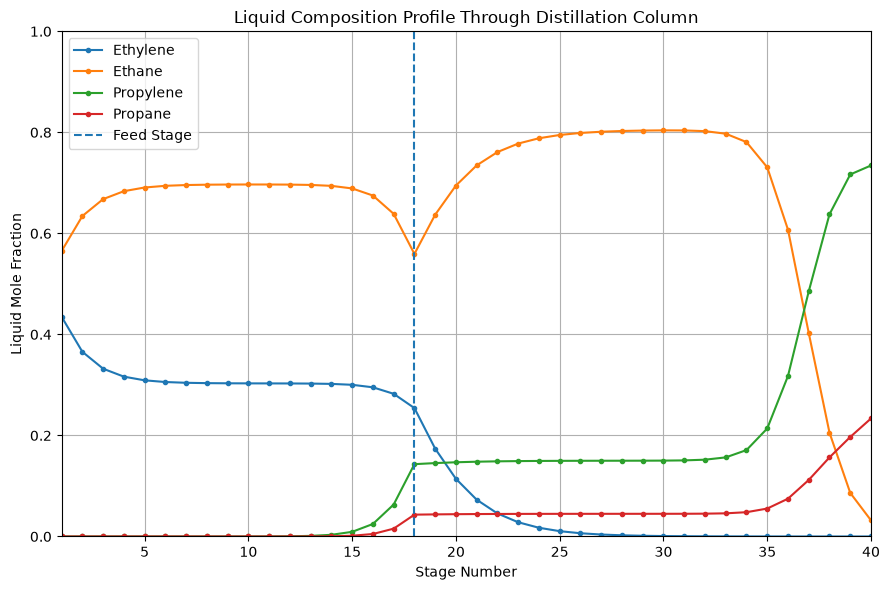

In [24]:
# ============================================================
# STAGE COMPOSITION PROFILE
# ============================================================

stages = np.arange(1, N + 1)

plt.figure(figsize=(9, 6))

for i, component in enumerate(components):

    plt.plot(
        stages,
        x_calc[:, i],
        marker="o",
        markersize=3,
        label=component
    )

# Mark feed stage
plt.axvline(
    x=feed_stage,
    linestyle="--",
    label="Feed Stage"
)

plt.xlabel("Stage Number")
plt.ylabel("Liquid Mole Fraction")
plt.title("Liquid Composition Profile Through Distillation Column")

plt.xlim(1, N)
plt.ylim(0, 1)

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
# ============================================================
# DISTILLATION COLUMN SIMULATOR
# TKINTER INTERFACE - PART 1
# ============================================================

import tkinter as tk
from tkinter import ttk

# ------------------------------------------------------------
# MAIN WINDOW
# ------------------------------------------------------------

root = tk.Tk()
root.title("Distillation Column Simulator")
root.geometry("1100x750")

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

title_label = tk.Label(
    root,
    text="Distillation Column Simulator",
    font=("Arial", 20, "bold")
)

title_label.pack(pady=10)


# ------------------------------------------------------------
# MAIN INPUT FRAME
# ------------------------------------------------------------

input_frame = tk.LabelFrame(
    root,
    text="Column Inputs",
    padx=15,
    pady=15
)

input_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)


# ------------------------------------------------------------
# FEED FLOW
# ------------------------------------------------------------

tk.Label(
    input_frame,
    text="Feed Flow (lbmol/hr)"
).grid(row=0, column=0, sticky="w", padx=5, pady=5)

feed_flow_entry = tk.Entry(input_frame, width=12)
feed_flow_entry.insert(0, "1000")
feed_flow_entry.grid(row=0, column=1, padx=5, pady=5)


# ------------------------------------------------------------
# FEED TEMPERATURE
# ------------------------------------------------------------

tk.Label(
    input_frame,
    text="Feed Temperature (°F)"
).grid(row=0, column=2, sticky="w", padx=5, pady=5)

feed_temp_entry = tk.Entry(input_frame, width=12)
feed_temp_entry.insert(0, "100")
feed_temp_entry.grid(row=0, column=3, padx=5, pady=5)


# ------------------------------------------------------------
# FEED PRESSURE
# ------------------------------------------------------------

tk.Label(
    input_frame,
    text="Feed Pressure (psia)"
).grid(row=0, column=4, sticky="w", padx=5, pady=5)

feed_pressure_entry = tk.Entry(input_frame, width=12)
feed_pressure_entry.insert(0, "392")
feed_pressure_entry.grid(row=0, column=5, padx=5, pady=5)


# ------------------------------------------------------------
# NUMBER OF STAGES
# ------------------------------------------------------------

tk.Label(
    input_frame,
    text="Number of Stages"
).grid(row=1, column=0, sticky="w", padx=5, pady=5)

stages_entry = tk.Entry(input_frame, width=12)
stages_entry.insert(0, "40")
stages_entry.grid(row=1, column=1, padx=5, pady=5)


# ------------------------------------------------------------
# FEED STAGE
# ------------------------------------------------------------

tk.Label(
    input_frame,
    text="Feed Stage"
).grid(row=1, column=2, sticky="w", padx=5, pady=5)

feed_stage_entry = tk.Entry(input_frame, width=12)
feed_stage_entry.insert(0, "18")
feed_stage_entry.grid(row=1, column=3, padx=5, pady=5)


# ------------------------------------------------------------
# REFLUX RATIO
# ------------------------------------------------------------

tk.Label(
    input_frame,
    text="Reflux Ratio"
).grid(row=1, column=4, sticky="w", padx=5, pady=5)

reflux_entry = tk.Entry(input_frame, width=12)
reflux_entry.insert(0, "1.16")
reflux_entry.grid(row=1, column=5, padx=5, pady=5)


# ------------------------------------------------------------
# DISTILLATE FLOW
# ------------------------------------------------------------

tk.Label(
    input_frame,
    text="Distillate Flow (lbmol/hr)"
).grid(row=2, column=0, sticky="w", padx=5, pady=5)

distillate_entry = tk.Entry(input_frame, width=12)
distillate_entry.insert(0, "850")
distillate_entry.grid(row=2, column=1, padx=5, pady=5)


# ------------------------------------------------------------
# TOP PRESSURE
# ------------------------------------------------------------

tk.Label(
    input_frame,
    text="Top Pressure (psia)"
).grid(row=2, column=2, sticky="w", padx=5, pady=5)

top_pressure_entry = tk.Entry(input_frame, width=12)
top_pressure_entry.insert(0, "392")
top_pressure_entry.grid(row=2, column=3, padx=5, pady=5)


# ------------------------------------------------------------
# COLUMN PRESSURE DROP
# ------------------------------------------------------------

tk.Label(
    input_frame,
    text="Pressure Drop (psi)"
).grid(row=2, column=4, sticky="w", padx=5, pady=5)

pressure_drop_entry = tk.Entry(input_frame, width=12)
pressure_drop_entry.insert(0, "7.25")
pressure_drop_entry.grid(row=2, column=5, padx=5, pady=5)


# ------------------------------------------------------------
# COMPONENT SELECTION FRAME
# ------------------------------------------------------------

component_frame = tk.LabelFrame(
    root,
    text="Component Selection",
    padx=15,
    pady=15
)

component_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)


available_components = list(component_data.keys())


tk.Label(
    component_frame,
    text="Light Key"
).grid(row=0, column=0, padx=5, pady=5)

light_key_box = ttk.Combobox(
    component_frame,
    values=available_components,
    state="readonly",
    width=18
)

light_key_box.set("Ethane")
light_key_box.grid(row=0, column=1, padx=5, pady=5)


tk.Label(
    component_frame,
    text="Heavy Key"
).grid(row=0, column=2, padx=5, pady=5)

heavy_key_box = ttk.Combobox(
    component_frame,
    values=available_components,
    state="readonly",
    width=18
)

heavy_key_box.set("Propylene")
heavy_key_box.grid(row=0, column=3, padx=5, pady=5)


# ------------------------------------------------------------
# PLACEHOLDER CALCULATE BUTTON
# ------------------------------------------------------------

calculate_button = tk.Button(
    root,
    text="CALCULATE COLUMN",
    font=("Arial", 12, "bold"),
    width=22
)

calculate_button.pack(pady=15)


# ------------------------------------------------------------
# START APPLICATION
# ------------------------------------------------------------

root.mainloop()

In [20]:
# ============================================================
# TKINTER INTERFACE - PART 2
# COMPONENT FEED INPUTS
# ============================================================

root = tk.Tk()
root.title("Distillation Column Simulator")
root.geometry("1100x800")

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

tk.Label(
    root,
    text="Distillation Column Simulator",
    font=("Arial", 20, "bold")
).pack(pady=10)


# ------------------------------------------------------------
# COLUMN INPUTS
# ------------------------------------------------------------

input_frame = tk.LabelFrame(
    root,
    text="Column Inputs",
    padx=15,
    pady=15
)

input_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

input_data = [
    ("Feed Flow (lbmol/hr)", "1000"),
    ("Feed Temperature (°F)", "100"),
    ("Feed Pressure (psia)", "392"),
    ("Number of Stages", "40"),
    ("Feed Stage", "18"),
    ("Reflux Ratio", "1.16"),
    ("Distillate Flow (lbmol/hr)", "850"),
    ("Top Pressure (psia)", "392"),
    ("Pressure Drop (psi)", "7.25")
]

entry_boxes = []

for index, (label_text, default_value) in enumerate(input_data):

    row = index // 3
    column = (index % 3) * 2

    tk.Label(
        input_frame,
        text=label_text
    ).grid(
        row=row,
        column=column,
        sticky="w",
        padx=5,
        pady=5
    )

    entry = tk.Entry(
        input_frame,
        width=12
    )

    entry.insert(0, default_value)

    entry.grid(
        row=row,
        column=column + 1,
        padx=5,
        pady=5
    )

    entry_boxes.append(entry)


# Give the entries useful names
feed_flow_entry = entry_boxes[0]
feed_temp_entry = entry_boxes[1]
feed_pressure_entry = entry_boxes[2]
stages_entry = entry_boxes[3]
feed_stage_entry = entry_boxes[4]
reflux_entry = entry_boxes[5]
distillate_entry = entry_boxes[6]
top_pressure_entry = entry_boxes[7]
pressure_drop_entry = entry_boxes[8]


# ------------------------------------------------------------
# FEED COMPONENTS
# ------------------------------------------------------------

component_frame = tk.LabelFrame(
    root,
    text="Feed Components",
    padx=15,
    pady=10
)

component_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

tk.Label(
    component_frame,
    text="Component"
).grid(row=0, column=0, padx=5)

tk.Label(
    component_frame,
    text="Mass Fraction"
).grid(row=0, column=1, padx=5)


available_components = list(component_data.keys())

component_boxes = []
fraction_entries = []


# Default test case
default_components = [
    "Ethylene",
    "Ethane",
    "Propylene",
    "Propane"
]

default_fractions = [
    "0.44",
    "0.36",
    "0.15",
    "0.05"
]


# Create 8 possible component rows
for i in range(8):

    component_box = ttk.Combobox(
        component_frame,
        values=[""] + available_components,
        state="readonly",
        width=20
    )

    component_box.grid(
        row=i + 1,
        column=0,
        padx=5,
        pady=3
    )

    fraction_entry = tk.Entry(
        component_frame,
        width=15
    )

    fraction_entry.grid(
        row=i + 1,
        column=1,
        padx=5,
        pady=3
    )

    # Fill first four rows with test case
    if i < 4:

        component_box.set(
            default_components[i]
        )

        fraction_entry.insert(
            0,
            default_fractions[i]
        )

    component_boxes.append(
        component_box
    )

    fraction_entries.append(
        fraction_entry
    )


# ------------------------------------------------------------
# LIGHT KEY / HEAVY KEY
# ------------------------------------------------------------

key_frame = tk.LabelFrame(
    root,
    text="Key Components",
    padx=15,
    pady=10
)

key_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)


tk.Label(
    key_frame,
    text="Light Key"
).grid(row=0, column=0, padx=5, pady=5)

light_key_box = ttk.Combobox(
    key_frame,
    values=available_components,
    state="readonly",
    width=20
)

light_key_box.set("Ethane")

light_key_box.grid(
    row=0,
    column=1,
    padx=5,
    pady=5
)


tk.Label(
    key_frame,
    text="Heavy Key"
).grid(row=0, column=2, padx=5, pady=5)

heavy_key_box = ttk.Combobox(
    key_frame,
    values=available_components,
    state="readonly",
    width=20
)

heavy_key_box.set("Propylene")

heavy_key_box.grid(
    row=0,
    column=3,
    padx=5,
    pady=5
)


# ------------------------------------------------------------
# CALCULATE BUTTON
# ------------------------------------------------------------
# ------------------------------------------------------------
# CALCULATE + CLEAR BUTTONS
# ------------------------------------------------------------

button_frame = tk.Frame(root)
button_frame.pack(pady=15)

calculate_button = tk.Button(
    button_frame,
    text="CALCULATE COLUMN",
    font=("Arial", 12, "bold"),
    width=22
)

calculate_button.pack(
    side="left",
    padx=10
)


def clear_results():

    # Clear calculated results
    for widget in results_frame.winfo_children():
        widget.destroy()

    # Clear graph
    for widget in graph_frame.winfo_children():
        widget.destroy()




root.mainloop()

Exception in Tkinter callback
Traceback (most recent call last):
  File "C:\Users\Paula\anaconda3\Lib\tkinter\__init__.py", line 2093, in __call__
    return self.func(*args)
           ~~~~~~~~~^^^^^^^
  File "C:\Users\Paula\AppData\Local\Temp\ipykernel_1852\2568151380.py", line 285, in clear_results
    for widget in results_frame.winfo_children():
                  ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\Paula\anaconda3\Lib\tkinter\__init__.py", line 1215, in winfo_children
    self.tk.call('winfo', 'children', self._w)):
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
_tkinter.TclError: can't invoke "winfo" command: application has been destroyed
Exception in Tkinter callback
Traceback (most recent call last):
  File "C:\Users\Paula\anaconda3\Lib\tkinter\__init__.py", line 2093, in __call__
    return self.func(*args)
           ~~~~~~~~~^^^^^^^
  File "C:\Users\Paula\AppData\Local\Temp\ipykernel_1852\2568151380.py", line 285, in clear_results
    for widget in results_frame

In [28]:
# ============================================================
# TKINTER CALCULATION FUNCTION
# ============================================================

from tkinter import messagebox

def calculate_column():

    try:
        # ----------------------------------------------------
        # READ COLUMN INPUTS
        # ----------------------------------------------------

        F_app = float(feed_flow_entry.get())
        T_feed_F_app = float(feed_temp_entry.get())
        P_feed_app = float(feed_pressure_entry.get())

        N_app = int(stages_entry.get())
        feed_stage_app = int(feed_stage_entry.get())

        R_app = float(reflux_entry.get())
        D_app = float(distillate_entry.get())

        P_top_app = float(top_pressure_entry.get())
        delta_P_app = float(pressure_drop_entry.get())


        # ----------------------------------------------------
        # READ COMPONENTS AND MASS FRACTIONS
        # ----------------------------------------------------

        components_app = []
        mass_fractions_app = []

        for box, entry in zip(
            component_boxes,
            fraction_entries
        ):

            component = box.get().strip()
            fraction_text = entry.get().strip()

            if component != "" and fraction_text != "":

                components_app.append(component)
                mass_fractions_app.append(
                    float(fraction_text)
                )


        mass_fractions_app = np.array(
            mass_fractions_app
        )


        # ----------------------------------------------------
        # CHECK COMPONENT INPUTS
        # ----------------------------------------------------

        if len(components_app) < 2:
            raise ValueError(
                "Select at least 2 components."
            )

        if len(components_app) > 8:
            raise ValueError(
                "Maximum number of components is 8."
            )

        if len(set(components_app)) != len(components_app):
            raise ValueError(
                "Each component can only be selected once."
            )

        if not np.isclose(
            np.sum(mass_fractions_app),
            1.0,
            atol=0.001
        ):
            raise ValueError(
                "Mass fractions must add to 1.000."
            )


        # ----------------------------------------------------
        # LIGHT KEY / HEAVY KEY
        # ----------------------------------------------------

        light_key_app = light_key_box.get()
        heavy_key_app = heavy_key_box.get()

        if light_key_app not in components_app:
            raise ValueError(
                "Light Key must be one of the feed components."
            )

        if heavy_key_app not in components_app:
            raise ValueError(
                "Heavy Key must be one of the feed components."
            )

        if light_key_app == heavy_key_app:
            raise ValueError(
                "Light Key and Heavy Key must be different."
            )


        # ----------------------------------------------------
        # BASIC INPUT CHECKS
        # ----------------------------------------------------

        check_inputs(
            F_app,
            D_app,
            N_app,
            feed_stage_app,
            mass_fractions_app
        )


        # ----------------------------------------------------
        # FEED CALCULATIONS
        # ----------------------------------------------------

        z_app = mass_to_mole_fractions(
            components_app,
            mass_fractions_app
        )

        T_feed_K_app = F_to_K(
            T_feed_F_app
        )

        K_feed_app = calculate_K_values(
            components_app,
            T_feed_K_app,
            P_feed_app
        )

        beta_app = calculate_vapor_fraction(
            z_app,
            K_feed_app
        )

        q_app = 1 - beta_app


        # ----------------------------------------------------
        # COLUMN FLOWS
        # ----------------------------------------------------

        B_app = F_app - D_app

        L_rect_app = R_app * D_app
        V_rect_app = L_rect_app + D_app

        L_strip_app = (
            L_rect_app
            + q_app * F_app
        )

        V_strip_app = (
            V_rect_app
            - beta_app * F_app
        )

        if V_strip_app <= 0:
            raise ValueError(
                "Calculated stripping vapor flow is zero or negative."
            )


        # ----------------------------------------------------
        # PRESSURE PROFILE
        # ----------------------------------------------------

        pressures_app = pressure_profile(
            P_top_app,
            delta_P_app,
            N_app
        )


        # ----------------------------------------------------
        # INITIAL COMPOSITION
        # ----------------------------------------------------

        NC_app = len(components_app)

        x_app = np.tile(
            z_app,
            (N_app, 1)
        )

        max_iterations_app = 100
        tolerance_app = 1e-8


        # ----------------------------------------------------
        # COLUMN ITERATION
        # ----------------------------------------------------

        for iteration_app in range(
            max_iterations_app
        ):

            x_old_app = x_app.copy()

            K_all_app = np.zeros(
                (N_app, NC_app)
            )

            T_stage_app = np.zeros(
                N_app
            )


            # Stage temperatures and K-values
            for j in range(N_app):

                x_temp_app = (
                    x_old_app[j, :]
                    / np.sum(x_old_app[j, :])
                )

                T_stage_app[j] = stage_temperature(
                    x_temp_app,
                    pressures_app[j],
                    components_app
                )

                K_all_app[j, :] = (
                    calculate_K_values(
                        components_app,
                        T_stage_app[j],
                        pressures_app[j]
                    )
                )


            # ------------------------------------------------
            # SOLVE COMPONENT BALANCES
            # ------------------------------------------------

            x_app = np.zeros(
                (N_app, NC_app)
            )

            for i in range(NC_app):

                A = np.zeros(
                    (N_app, N_app)
                )

                b = np.zeros(
                    N_app
                )


                # TOP STAGE
                A[0, 0] = -(
                    L_rect_app
                    + D_app * K_all_app[0, i]
                )

                A[0, 1] = (
                    V_rect_app
                    * K_all_app[1, i]
                )


                # INTERNAL STAGES
                for j in range(
                    1,
                    N_app - 1
                ):

                    # Rectifying section
                    if j < feed_stage_app - 1:

                        A[j, j - 1] = (
                            L_rect_app
                        )

                        A[j, j] = -(
                            L_rect_app
                            + V_rect_app
                            * K_all_app[j, i]
                        )

                        A[j, j + 1] = (
                            V_rect_app
                            * K_all_app[j + 1, i]
                        )


                    # Feed stage
                    elif j == feed_stage_app - 1:

                        A[j, j - 1] = (
                            L_rect_app
                        )

                        A[j, j] = -(
                            L_strip_app
                            + V_rect_app
                            * K_all_app[j, i]
                        )

                        A[j, j + 1] = (
                            V_strip_app
                            * K_all_app[j + 1, i]
                        )

                        b[j] = -(
                            F_app * z_app[i]
                        )


                    # Stripping section
                    else:

                        A[j, j - 1] = (
                            L_strip_app
                        )

                        A[j, j] = -(
                            L_strip_app
                            + V_strip_app
                            * K_all_app[j, i]
                        )

                        A[j, j + 1] = (
                            V_strip_app
                            * K_all_app[j + 1, i]
                        )


                # BOTTOM / KETTLE REBOILER
                A[N_app - 1, N_app - 2] = (
                    L_strip_app
                )

                A[N_app - 1, N_app - 1] = -(
                    V_strip_app
                    * K_all_app[N_app - 1, i]
                    + B_app
                )


                x_app[:, i] = np.linalg.solve(
                    A,
                    b
                )


            # ------------------------------------------------
            # CONVERGENCE
            # ------------------------------------------------

            error_app = np.max(
                np.abs(
                    x_app - x_old_app
                )
            )

            if error_app < tolerance_app:
                break


        # ----------------------------------------------------
        # PRODUCT COMPOSITIONS
        # ----------------------------------------------------

        x_D_app = (
            K_all_app[0, :]
            * x_app[0, :]
        )

        x_B_app = (
            x_app[-1, :].copy()
        )


        # ----------------------------------------------------
        # COMPONENT BALANCE CHECK
        # ----------------------------------------------------

        balance_errors_app = (
            F_app * z_app
            - D_app * x_D_app
            - B_app * x_B_app
        )

        max_balance_error_app = np.max(
            np.abs(balance_errors_app)
        )


        # ----------------------------------------------------
        # KEY COMPONENT RESULTS
        # ----------------------------------------------------

        LK_app = components_app.index(
            light_key_app
        )

        HK_app = components_app.index(
            heavy_key_app
        )

        LK_purity_app = (
            x_D_app[LK_app] * 100
        )

        HK_purity_app = (
            x_B_app[HK_app] * 100
        )

        LK_recovery_app = (
            D_app * x_D_app[LK_app]
            / (F_app * z_app[LK_app])
            * 100
        )

        HK_recovery_app = (
            B_app * x_B_app[HK_app]
            / (F_app * z_app[HK_app])
            * 100
        )


        # ----------------------------------------------------
        # PRINT TEST RESULTS
        # ----------------------------------------------------

        print("\n========== APP CALCULATION ==========")

        print(
            "Iterations:",
            iteration_app + 1
        )

        print(
            "Convergence error:",
            error_app
        )

        print(
            "Maximum component balance error:",
            max_balance_error_app
        )

        print("\nComponent       Distillate      Bottoms")

        for i, component in enumerate(
            components_app
        ):

            print(
                f"{component:<15}"
                f"{x_D_app[i]:>12.4f}"
                f"{x_B_app[i]:>13.4f}"
            )

        print(
            "\nLight Key purity:",
            round(LK_purity_app, 2),
            "%"
        )

        print(
            "Light Key recovery:",
            round(LK_recovery_app, 2),
            "%"
        )

        print(
            "Heavy Key purity:",
            round(HK_purity_app, 2),
            "%"
        )

        print(
            "Heavy Key recovery:",
            round(HK_recovery_app, 2),
            "%"
        )


    except Exception as error:

        messagebox.showerror(
            "Calculation Error",
            str(error)
        )


print("Tkinter calculation function loaded.")

Tkinter calculation function loaded.


In [29]:
# ============================================================
# CONNECT CALCULATE BUTTON AND RUN APP
# ============================================================

# Connect the button to the calculation function
calculate_button.config(
    command=calculate_column
)

# Start the Tkinter application
root.mainloop()

TclError: invalid command name ".!button"

In [30]:
# ============================================================
# REOPEN APP WITH WORKING CALCULATE BUTTON
# ============================================================

root = tk.Tk()
root.title("Distillation Column Simulator")
root.geometry("1100x800")


# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

tk.Label(
    root,
    text="Distillation Column Simulator",
    font=("Arial", 20, "bold")
).pack(pady=10)


# ------------------------------------------------------------
# COLUMN INPUTS
# ------------------------------------------------------------

input_frame = tk.LabelFrame(
    root,
    text="Column Inputs",
    padx=15,
    pady=15
)

input_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)


input_data = [
    ("Feed Flow (lbmol/hr)", "1000"),
    ("Feed Temperature (°F)", "100"),
    ("Feed Pressure (psia)", "392"),
    ("Number of Stages", "40"),
    ("Feed Stage", "18"),
    ("Reflux Ratio", "1.16"),
    ("Distillate Flow (lbmol/hr)", "850"),
    ("Top Pressure (psia)", "392"),
    ("Pressure Drop (psi)", "7.25")
]

entry_boxes = []

for index, (label_text, default_value) in enumerate(input_data):

    row = index // 3
    column = (index % 3) * 2

    tk.Label(
        input_frame,
        text=label_text
    ).grid(
        row=row,
        column=column,
        sticky="w",
        padx=5,
        pady=5
    )

    entry = tk.Entry(
        input_frame,
        width=12
    )

    entry.insert(
        0,
        default_value
    )

    entry.grid(
        row=row,
        column=column + 1,
        padx=5,
        pady=5
    )

    entry_boxes.append(entry)


feed_flow_entry = entry_boxes[0]
feed_temp_entry = entry_boxes[1]
feed_pressure_entry = entry_boxes[2]
stages_entry = entry_boxes[3]
feed_stage_entry = entry_boxes[4]
reflux_entry = entry_boxes[5]
distillate_entry = entry_boxes[6]
top_pressure_entry = entry_boxes[7]
pressure_drop_entry = entry_boxes[8]


# ------------------------------------------------------------
# FEED COMPONENTS
# ------------------------------------------------------------

component_frame = tk.LabelFrame(
    root,
    text="Feed Components",
    padx=15,
    pady=10
)

component_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)


tk.Label(
    component_frame,
    text="Component"
).grid(row=0, column=0, padx=5)

tk.Label(
    component_frame,
    text="Mass Fraction"
).grid(row=0, column=1, padx=5)


available_components = list(
    component_data.keys()
)

component_boxes = []
fraction_entries = []


default_components = [
    "Ethylene",
    "Ethane",
    "Propylene",
    "Propane"
]

default_fractions = [
    "0.44",
    "0.36",
    "0.15",
    "0.05"
]


for i in range(8):

    component_box = ttk.Combobox(
        component_frame,
        values=[""] + available_components,
        state="readonly",
        width=20
    )

    component_box.grid(
        row=i + 1,
        column=0,
        padx=5,
        pady=3
    )

    fraction_entry = tk.Entry(
        component_frame,
        width=15
    )

    fraction_entry.grid(
        row=i + 1,
        column=1,
        padx=5,
        pady=3
    )

    if i < 4:

        component_box.set(
            default_components[i]
        )

        fraction_entry.insert(
            0,
            default_fractions[i]
        )

    component_boxes.append(
        component_box
    )

    fraction_entries.append(
        fraction_entry
    )


# ------------------------------------------------------------
# KEY COMPONENTS
# ------------------------------------------------------------

key_frame = tk.LabelFrame(
    root,
    text="Key Components",
    padx=15,
    pady=10
)

key_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)


tk.Label(
    key_frame,
    text="Light Key"
).grid(row=0, column=0, padx=5, pady=5)

light_key_box = ttk.Combobox(
    key_frame,
    values=available_components,
    state="readonly",
    width=20
)

light_key_box.set("Ethane")

light_key_box.grid(
    row=0,
    column=1,
    padx=5,
    pady=5
)


tk.Label(
    key_frame,
    text="Heavy Key"
).grid(row=0, column=2, padx=5, pady=5)

heavy_key_box = ttk.Combobox(
    key_frame,
    values=available_components,
    state="readonly",
    width=20
)

heavy_key_box.set("Propylene")

heavy_key_box.grid(
    row=0,
    column=3,
    padx=5,
    pady=5
)


# ------------------------------------------------------------
# WORKING CALCULATE BUTTON
# ------------------------------------------------------------

calculate_button = tk.Button(
    root,
    text="CALCULATE COLUMN",
    font=("Arial", 12, "bold"),
    width=22,
    command=calculate_column
)

calculate_button.pack(
    pady=15
)


# ------------------------------------------------------------
# RUN APP
# ------------------------------------------------------------

root.mainloop()


========== APP CALCULATION ==========
Iterations: 74
Convergence error: 9.83255593611787e-09
Maximum component balance error: 8.624441018658703e-13

Component       Distillate      Bottoms
Ethylene             0.5703       0.0000
Ethane               0.4297       0.0320
Propylene            0.0000       0.7344
Propane              0.0000       0.2336

Light Key purity: 42.97 %
Light Key recovery: 98.7 %
Heavy Key purity: 73.44 %
Heavy Key recovery: 100.0 %

========== APP CALCULATION ==========
Iterations: 74
Convergence error: 9.83255593611787e-09
Maximum component balance error: 8.624441018658703e-13

Component       Distillate      Bottoms
Ethylene             0.5703       0.0000
Ethane               0.4297       0.0320
Propylene            0.0000       0.7344
Propane              0.0000       0.2336

Light Key purity: 42.97 %
Light Key recovery: 98.7 %
Heavy Key purity: 73.44 %
Heavy Key recovery: 100.0 %


In [7]:
# ============================================================
# RESULTS DISPLAY FOR TKINTER APP
# ============================================================

def show_results(
    components,
    x_D,
    x_B,
    D,
    B,
    light_key,
    heavy_key,
    LK_purity,
    LK_recovery,
    HK_purity,
    HK_recovery,
    iterations,
    balance_error
):

    # Remove old results if they exist
    for widget in results_frame.winfo_children():
        widget.destroy()

    # --------------------------------------------------------
    # PRODUCT FLOW RESULTS
    # --------------------------------------------------------

    tk.Label(
        results_frame,
        text=f"Distillate Flow: {D:.2f} lbmol/hr",
        font=("Arial", 10, "bold")
    ).grid(
        row=0,
        column=0,
        columnspan=2,
        sticky="w",
        padx=10,
        pady=5
    )

    tk.Label(
        results_frame,
        text=f"Bottoms Flow: {B:.2f} lbmol/hr",
        font=("Arial", 10, "bold")
    ).grid(
        row=0,
        column=2,
        columnspan=2,
        sticky="w",
        padx=10,
        pady=5
    )


    # --------------------------------------------------------
    # PRODUCT COMPOSITION TABLE
    # --------------------------------------------------------

    tk.Label(
        results_frame,
        text="Component",
        font=("Arial", 10, "bold")
    ).grid(row=1, column=0, padx=10, pady=4)

    tk.Label(
        results_frame,
        text="Distillate",
        font=("Arial", 10, "bold")
    ).grid(row=1, column=1, padx=10, pady=4)

    tk.Label(
        results_frame,
        text="Bottoms",
        font=("Arial", 10, "bold")
    ).grid(row=1, column=2, padx=10, pady=4)


    for i, component in enumerate(components):

        tk.Label(
            results_frame,
            text=component
        ).grid(
            row=i + 2,
            column=0,
            padx=10,
            pady=2
        )

        tk.Label(
            results_frame,
            text=f"{x_D[i]:.4f}"
        ).grid(
            row=i + 2,
            column=1,
            padx=10,
            pady=2
        )

        tk.Label(
            results_frame,
            text=f"{x_B[i]:.4f}"
        ).grid(
            row=i + 2,
            column=2,
            padx=10,
            pady=2
        )


    # --------------------------------------------------------
    # KEY COMPONENT RESULTS
    # --------------------------------------------------------
         # --------------------------------------------------------
    # KEY COMPONENT RESULTS
    # --------------------------------------------------------

    key_row = len(components) + 3

    tk.Label(
        results_frame,
        text=f"Light Key: {light_key}",
        font=("Arial", 10, "bold")
    ).grid(
        row=key_row,
        column=0,
        sticky="w",
        padx=10,
        pady=5
    )

    tk.Label(
        results_frame,
        text=f"Purity: {LK_purity * 100:.2f}%"
    ).grid(
        row=key_row,
        column=1,
        padx=10,
        pady=5
    )

    tk.Label(
        results_frame,
        text=f"Recovery: {LK_recovery * 100:.2f}%"
    ).grid(
        row=key_row,
        column=2,
        padx=10,
        pady=5
    )

    tk.Label(
        results_frame,
        text=f"Heavy Key: {heavy_key}",
        font=("Arial", 10, "bold")
    ).grid(
        row=key_row + 1,
        column=0,
        sticky="w",
        padx=10,
        pady=5
    )

    tk.Label(
        results_frame,
        text=f"Purity: {HK_purity * 100:.2f}%"
    ).grid(
        row=key_row + 1,
        column=1,
        padx=10,
        pady=5
    )

    tk.Label(
        results_frame,
        text=f"Recovery: {HK_recovery * 100:.2f}%"
    ).grid(
        row=key_row + 1,
        column=2,
        padx=10,
        pady=5
    )
    # --------------------------------------------------------
    # SOLVER INFORMATION
    # --------------------------------------------------------

    tk.Label(
        results_frame,
        text=f"Iterations: {iterations}"
    ).grid(
        row=key_row + 2,
        column=0,
        padx=10,
        pady=5
    )

    tk.Label(
        results_frame,
        text=f"Max Balance Error: {balance_error:.2e}"
    ).grid(
        row=key_row + 2,
        column=1,
        columnspan=2,
        padx=10,
        pady=5
    )


print("Results display function loaded.")

Results display function loaded.


In [19]:
# ============================================================
# CONNECT RESULTS DISPLAY TO CALCULATION
# ============================================================

# Save the original calculation function
calculate_column_original = calculate_column


def calculate_and_display():

    try:
        # Run the existing calculation
        calculate_column_original()

        # Read current app inputs
        F_app = float(feed_flow_entry.get())
        D_app = float(distillate_entry.get())

        B_app = F_app - D_app

        components_app = []
        mass_fractions_app = []

        for box, entry in zip(
            component_boxes,
            fraction_entries
        ):

            component = box.get().strip()
            fraction = entry.get().strip()

            if component != "" and fraction != "":
                components_app.append(component)
                mass_fractions_app.append(
                    float(fraction)
                )

        mass_fractions_app = np.array(
            mass_fractions_app
        )

        z_app = mass_to_mole_fractions(
            components_app,
            mass_fractions_app
        )

        light_key_app = light_key_box.get()
        heavy_key_app = heavy_key_box.get()

        LK_app = components_app.index(
            light_key_app
        )

        HK_app = components_app.index(
            heavy_key_app
        )

        # Use results from calculation
        x_D_display = (
            K_all_app[0, :]
            * x_app[0, :]
        )

        x_B_display = x_app[-1, :]

        LK_purity_display = (
            x_D_display[LK_app] * 100
        )

        HK_purity_display = (
            x_B_display[HK_app] * 100
        )

        LK_recovery_display = (
            D_app * x_D_display[LK_app]
            / (F_app * z_app[LK_app])
            * 100
        )

        HK_recovery_display = (
            B_app * x_B_display[HK_app]
            / (F_app * z_app[HK_app])
            * 100
        )

        balance_errors_display = (
            F_app * z_app
            - D_app * x_D_display
            - B_app * x_B_display
        )

        max_balance_display = np.max(
            np.abs(balance_errors_display)
        )

        show_results(
            components_app,
            x_D_display,
            x_B_display,
            D_app,
            B_app,
            light_key_app,
            heavy_key_app,
            LK_purity_display,
            LK_recovery_display,
            HK_purity_display,
            HK_recovery_display,
            iteration_app + 1,
            max_balance_display
        )

    except Exception as error:

        messagebox.showerror(
            "Display Error",
            str(error)
        )


print("Calculation and results display connected.")


NameError: name 'calculate_column' is not defined

In [33]:
# ============================================================
# CALCULATION FUNCTION THAT RETURNS RESULTS
# ============================================================

def run_column_calculation():

    # --------------------------------------------------------
    # READ COLUMN INPUTS
    # --------------------------------------------------------

    F_app = float(feed_flow_entry.get())
    T_feed_F_app = float(feed_temp_entry.get())
    P_feed_app = float(feed_pressure_entry.get())

    N_app = int(stages_entry.get())
    feed_stage_app = int(feed_stage_entry.get())

    R_app = float(reflux_entry.get())
    D_app = float(distillate_entry.get())

    P_top_app = float(top_pressure_entry.get())
    delta_P_app = float(pressure_drop_entry.get())


    # --------------------------------------------------------
    # READ COMPONENTS
    # --------------------------------------------------------

    components_app = []
    mass_fractions_app = []

    for box, entry in zip(
        component_boxes,
        fraction_entries
    ):

        component = box.get().strip()
        fraction = entry.get().strip()

        if component != "" and fraction != "":

            components_app.append(component)
            mass_fractions_app.append(
                float(fraction)
            )


    mass_fractions_app = np.array(
        mass_fractions_app
    )


    # --------------------------------------------------------
    # INPUT CHECKS
    # --------------------------------------------------------

    if len(components_app) < 2:
        raise ValueError(
            "Select at least 2 components."
        )

    if len(set(components_app)) != len(components_app):
        raise ValueError(
            "Each component can only be selected once."
        )

    if not np.isclose(
        np.sum(mass_fractions_app),
        1.0,
        atol=0.001
    ):
        raise ValueError(
            "Mass fractions must add to 1.000."
        )

    light_key_app = light_key_box.get()
    heavy_key_app = heavy_key_box.get()

    if light_key_app not in components_app:
        raise ValueError(
            "Light Key must be a feed component."
        )

    if heavy_key_app not in components_app:
        raise ValueError(
            "Heavy Key must be a feed component."
        )

    if light_key_app == heavy_key_app:
        raise ValueError(
            "Light Key and Heavy Key must be different."
        )

    check_inputs(
        F_app,
        D_app,
        N_app,
        feed_stage_app,
        mass_fractions_app
    )


    # --------------------------------------------------------
    # FEED
    # --------------------------------------------------------

    z_app = mass_to_mole_fractions(
        components_app,
        mass_fractions_app
    )

    T_feed_K_app = F_to_K(
        T_feed_F_app
    )

    K_feed_app = calculate_K_values(
        components_app,
        T_feed_K_app,
        P_feed_app
    )

    beta_app = calculate_vapor_fraction(
        z_app,
        K_feed_app
    )

    q_app = 1 - beta_app


    # --------------------------------------------------------
    # COLUMN FLOWS
    # --------------------------------------------------------

    B_app = F_app - D_app

    L_rect_app = R_app * D_app
    V_rect_app = L_rect_app + D_app

    L_strip_app = (
        L_rect_app
        + q_app * F_app
    )

    V_strip_app = (
        V_rect_app
        - beta_app * F_app
    )

    if V_strip_app <= 0:
        raise ValueError(
            "Calculated stripping vapor flow is zero or negative."
        )


    # --------------------------------------------------------
    # PRESSURES
    # --------------------------------------------------------

    pressures_app = pressure_profile(
        P_top_app,
        delta_P_app,
        N_app
    )


    # --------------------------------------------------------
    # COLUMN SOLVER
    # --------------------------------------------------------

    NC_app = len(components_app)

    x_app = np.tile(
        z_app,
        (N_app, 1)
    )

    max_iterations_app = 100
    tolerance_app = 1e-8


    for iteration_app in range(
        max_iterations_app
    ):

        x_old_app = x_app.copy()

        K_all_app = np.zeros(
            (N_app, NC_app)
        )

        T_stage_app = np.zeros(
            N_app
        )


        # Stage temperatures and K-values
        for j in range(N_app):

            x_temp_app = (
                x_old_app[j, :]
                / np.sum(x_old_app[j, :])
            )

            T_stage_app[j] = stage_temperature(
                x_temp_app,
                pressures_app[j],
                components_app
            )

            K_all_app[j, :] = calculate_K_values(
                components_app,
                T_stage_app[j],
                pressures_app[j]
            )


        # ----------------------------------------------------
        # COMPONENT BALANCES
        # ----------------------------------------------------

        x_app = np.zeros(
            (N_app, NC_app)
        )

        for i in range(NC_app):

            A = np.zeros(
                (N_app, N_app)
            )

            b = np.zeros(
                N_app
            )


            # TOP STAGE
            A[0, 0] = -(
                L_rect_app
                + D_app * K_all_app[0, i]
            )

            A[0, 1] = (
                V_rect_app
                * K_all_app[1, i]
            )


            # INTERNAL STAGES
            for j in range(
                1,
                N_app - 1
            ):

                # Rectifying section
                if j < feed_stage_app - 1:

                    A[j, j - 1] = L_rect_app

                    A[j, j] = -(
                        L_rect_app
                        + V_rect_app
                        * K_all_app[j, i]
                    )

                    A[j, j + 1] = (
                        V_rect_app
                        * K_all_app[j + 1, i]
                    )


                # Feed stage
                elif j == feed_stage_app - 1:

                    A[j, j - 1] = L_rect_app

                    A[j, j] = -(
                        L_strip_app
                        + V_rect_app
                        * K_all_app[j, i]
                    )

                    A[j, j + 1] = (
                        V_strip_app
                        * K_all_app[j + 1, i]
                    )

                    b[j] = -(
                        F_app * z_app[i]
                    )


                # Stripping section
                else:

                    A[j, j - 1] = L_strip_app

                    A[j, j] = -(
                        L_strip_app
                        + V_strip_app
                        * K_all_app[j, i]
                    )

                    A[j, j + 1] = (
                        V_strip_app
                        * K_all_app[j + 1, i]
                    )


            # BOTTOM / KETTLE REBOILER
            A[N_app - 1, N_app - 2] = (
                L_strip_app
            )

            A[N_app - 1, N_app - 1] = -(
                V_strip_app
                * K_all_app[N_app - 1, i]
                + B_app
            )


            x_app[:, i] = np.linalg.solve(
                A,
                b
            )


        # ----------------------------------------------------
        # CONVERGENCE
        # ----------------------------------------------------

        error_app = np.max(
            np.abs(
                x_app - x_old_app
            )
        )

        if error_app < tolerance_app:
            break


    # --------------------------------------------------------
    # PRODUCTS
    # --------------------------------------------------------

    x_D_app = (
        K_all_app[0, :]
        * x_app[0, :]
    )

    x_B_app = (
        x_app[-1, :].copy()
    )


    # --------------------------------------------------------
    # BALANCE CHECK
    # --------------------------------------------------------

    balance_errors_app = (
        F_app * z_app
        - D_app * x_D_app
        - B_app * x_B_app
    )

    max_balance_error_app = np.max(
        np.abs(balance_errors_app)
    )


    # --------------------------------------------------------
    # KEY RESULTS
    # --------------------------------------------------------

    LK_app = components_app.index(
        light_key_app
    )

    HK_app = components_app.index(
        heavy_key_app
    )

    LK_purity_app = (
        x_D_app[LK_app] * 100
    )

    HK_purity_app = (
        x_B_app[HK_app] * 100
    )

    LK_recovery_app = (
        D_app * x_D_app[LK_app]
        / (F_app * z_app[LK_app])
        * 100
    )

    HK_recovery_app = (
        B_app * x_B_app[HK_app]
        / (F_app * z_app[HK_app])
        * 100
    )


    # --------------------------------------------------------
    # RETURN EVERYTHING NEEDED BY APP
    # --------------------------------------------------------

    return {
        "components": components_app,
        "x_D": x_D_app,
        "x_B": x_B_app,
        "x_stage": x_app,
        "temperatures": T_stage_app,
        "pressures": pressures_app,

        "D": D_app,
        "B": B_app,

        "light_key": light_key_app,
        "heavy_key": heavy_key_app,

        "LK_purity": LK_purity_app,
        "LK_recovery": LK_recovery_app,

        "HK_purity": HK_purity_app,
        "HK_recovery": HK_recovery_app,

        "iterations": iteration_app + 1,
        "convergence_error": error_app,
        "balance_error": max_balance_error_app,

        "feed_stage": feed_stage_app
    }


print("Column calculation return function loaded.")

Column calculation return function loaded.


In [34]:
# ============================================================
# DISPLAY CALCULATED RESULTS IN THE APP
# ============================================================

def calculate_and_show():

    try:

        results = run_column_calculation()

        show_results(
            results["components"],
            results["x_D"],
            results["x_B"],
            results["D"],
            results["B"],
            results["light_key"],
            results["heavy_key"],
            results["LK_purity"],
            results["LK_recovery"],
            results["HK_purity"],
            results["HK_recovery"],
            results["iterations"],
            results["balance_error"]
        )

    except Exception as error:

        messagebox.showerror(
            "Calculation Error",
            str(error)
        )


print("Calculate-and-display function loaded.")

Calculate-and-display function loaded.


In [35]:
# ============================================================
# FINAL APP WINDOW WITH RESULTS SECTION
# ============================================================

root = tk.Tk()
root.title("Distillation Column Simulator")
root.geometry("1100x900")


# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

tk.Label(
    root,
    text="Distillation Column Simulator",
    font=("Arial", 20, "bold")
).pack(pady=10)


# ------------------------------------------------------------
# COLUMN INPUTS
# ------------------------------------------------------------

input_frame = tk.LabelFrame(
    root,
    text="Column Inputs",
    padx=15,
    pady=15
)

input_frame.pack(
    padx=20,
    pady=5,
    fill="x"
)

input_data = [
    ("Feed Flow (lbmol/hr)", "1000"),
    ("Feed Temperature (°F)", "100"),
    ("Feed Pressure (psia)", "392"),
    ("Number of Stages", "40"),
    ("Feed Stage", "18"),
    ("Reflux Ratio", "1.16"),
    ("Distillate Flow (lbmol/hr)", "850"),
    ("Top Pressure (psia)", "392"),
    ("Pressure Drop (psi)", "7.25")
]

entry_boxes = []

for index, (label_text, default_value) in enumerate(input_data):

    row = index // 3
    column = (index % 3) * 2

    tk.Label(
        input_frame,
        text=label_text
    ).grid(
        row=row,
        column=column,
        sticky="w",
        padx=5,
        pady=5
    )

    entry = tk.Entry(
        input_frame,
        width=12
    )

    entry.insert(0, default_value)

    entry.grid(
        row=row,
        column=column + 1,
        padx=5,
        pady=5
    )

    entry_boxes.append(entry)


feed_flow_entry = entry_boxes[0]
feed_temp_entry = entry_boxes[1]
feed_pressure_entry = entry_boxes[2]
stages_entry = entry_boxes[3]
feed_stage_entry = entry_boxes[4]
reflux_entry = entry_boxes[5]
distillate_entry = entry_boxes[6]
top_pressure_entry = entry_boxes[7]
pressure_drop_entry = entry_boxes[8]


# ------------------------------------------------------------
# FEED COMPONENTS
# ------------------------------------------------------------

component_frame = tk.LabelFrame(
    root,
    text="Feed Components",
    padx=15,
    pady=10
)

component_frame.pack(
    padx=20,
    pady=5,
    fill="x"
)

tk.Label(
    component_frame,
    text="Component"
).grid(row=0, column=0, padx=5)

tk.Label(
    component_frame,
    text="Mass Fraction"
).grid(row=0, column=1, padx=5)


available_components = list(component_data.keys())

component_boxes = []
fraction_entries = []

default_components = [
    "Ethylene",
    "Ethane",
    "Propylene",
    "Propane"
]

default_fractions = [
    "0.44",
    "0.36",
    "0.15",
    "0.05"
]


for i in range(8):

    component_box = ttk.Combobox(
        component_frame,
        values=[""] + available_components,
        state="readonly",
        width=20
    )

    component_box.grid(
        row=i + 1,
        column=0,
        padx=5,
        pady=2
    )

    fraction_entry = tk.Entry(
        component_frame,
        width=15
    )

    fraction_entry.grid(
        row=i + 1,
        column=1,
        padx=5,
        pady=2
    )

    if i < 4:

        component_box.set(
            default_components[i]
        )

        fraction_entry.insert(
            0,
            default_fractions[i]
        )

    component_boxes.append(component_box)
    fraction_entries.append(fraction_entry)


# ------------------------------------------------------------
# KEY COMPONENTS
# ------------------------------------------------------------

key_frame = tk.LabelFrame(
    root,
    text="Key Components",
    padx=15,
    pady=10
)

key_frame.pack(
    padx=20,
    pady=5,
    fill="x"
)


tk.Label(
    key_frame,
    text="Light Key"
).grid(row=0, column=0, padx=5)

light_key_box = ttk.Combobox(
    key_frame,
    values=available_components,
    state="readonly",
    width=20
)

light_key_box.set("Ethane")
light_key_box.grid(
    row=0,
    column=1,
    padx=5
)


tk.Label(
    key_frame,
    text="Heavy Key"
).grid(row=0, column=2, padx=5)

heavy_key_box = ttk.Combobox(
    key_frame,
    values=available_components,
    state="readonly",
    width=20
)

heavy_key_box.set("Propylene")
heavy_key_box.grid(
    row=0,
    column=3,
    padx=5
)


# ------------------------------------------------------------
# CALCULATE BUTTON
# ------------------------------------------------------------

calculate_button = tk.Button(
    root,
    text="CALCULATE COLUMN",
    font=("Arial", 12, "bold"),
    width=22,
    command=calculate_and_show
)

calculate_button.pack(
    pady=8
)


# ------------------------------------------------------------
# RESULTS SECTION
# ------------------------------------------------------------

results_frame = tk.LabelFrame(
    root,
    text="Calculated Results",
    padx=15,
    pady=10
)

results_frame.pack(
    padx=20,
    pady=5,
    fill="both",
    expand=True
)


tk.Label(
    results_frame,
    text="Enter column conditions and click CALCULATE COLUMN."
).pack(
    pady=15
)


# ------------------------------------------------------------
# RUN APPLICATION
# ------------------------------------------------------------

root.mainloop()

KeyboardInterrupt: 

In [8]:
# ============================================================
# GRAPH DISPLAY FUNCTION
# ============================================================

from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from matplotlib.figure import Figure

def show_graph(results):

    # Clear old graph
    for widget in graph_frame.winfo_children():
        widget.destroy()

    components_graph = results["components"]
    x_stage_graph = results["x_stage"]
    feed_stage_graph = results["feed_stage"]

    N_graph = x_stage_graph.shape[0]
    stages_graph = np.arange(1, N_graph + 1)

    # Create graph
    figure = Figure(figsize=(7.5, 4.5), dpi=100)
    plot = figure.add_subplot(111)

    # Plot component profiles
    for i, component in enumerate(components_graph):
        plot.plot(
            stages_graph,
            x_stage_graph[:, i],
            marker="o",
            markersize=3,
            label=component
        )

    # Feed stage
    plot.axvline(
        feed_stage_graph,
        linestyle="--",
        label="Feed Stage"
    )

    # Labels
    plot.set_title(
        "Liquid Composition Profile Through Distillation Column"
    )

    plot.set_xlabel("Stage Number")
    plot.set_ylabel("Liquid Mole Fraction")

    plot.set_xlim(1, N_graph)
    plot.set_ylim(0, 1)

    plot.grid(True)
    plot.legend()
    figure.tight_layout()

    # Put graph inside Tkinter
    canvas = FigureCanvasTkAgg(
        figure,
        master=graph_frame
    )

    canvas.draw()
    canvas.get_tk_widget().pack(
        fill="both",
        expand=True
    )

print("Graph display function loaded.")

Graph display function loaded.


In [11]:
# ============================================================
# CALCULATE + RESULTS + GRAPH
# ============================================================

def calculate_results_and_graph():
    try:

        # Run calculation once
        results = run_column_calculation()

        # Display numerical results
        show_results(
            results["components"],
            results["x_D"],
            results["x_B"],
            results["D"],
            results["B"],
            results["light_key"],
            results["heavy_key"],
            results["LK_purity"],
            results["LK_recovery"],
            results["HK_purity"],
            results["HK_recovery"],
            results["iterations"],
            results["balance_error"]
        )

        # Display composition graph
        show_graph(results)

        # Display tower visual
        show_tower(results)

    except Exception as error:

        messagebox.showerror(
            "Calculation Error",
            str(error)
        )


print("Results, graph, and tower connected.")
   

Results, graph, and tower connected.


In [39]:
# ============================================================
# ADD GRAPH SECTION AND RUN APP
# ============================================================

# Create graph section
graph_frame = tk.LabelFrame(
    root,
    text="Stage Composition Profile",
    padx=10,
    pady=10
)

graph_frame.pack(
    padx=20,
    pady=10,
    fill="both",
    expand=True
)

# Change Calculate button to run:
# calculation + results + graph
calculate_button.config(
    command=calculate_results_and_graph
)
# Make window larger for graph
root.geometry("1100x1000")

# Run application
root.mainloop()

KeyboardInterrupt: 

In [40]:
# ============================================================
# NEW APP WINDOW
# ============================================================

root = tk.Tk()
root.title("Distillation Column Simulator")
root.geometry("1100x850")

# Main canvas
main_canvas = tk.Canvas(root)

# Vertical scrollbar
scrollbar = ttk.Scrollbar(
    root,
    orient="vertical",
    command=main_canvas.yview
)

# Scrollable frame
scrollable_frame = tk.Frame(main_canvas)

scrollable_frame.bind(
    "<Configure>",
    lambda event: main_canvas.configure(
        scrollregion=main_canvas.bbox("all")
    )
)

main_canvas.create_window(
    (0, 0),
    window=scrollable_frame,
    anchor="nw"
)

main_canvas.configure(
    yscrollcommand=scrollbar.set
)

main_canvas.pack(
    side="left",
    fill="both",
    expand=True
)

scrollbar.pack(
    side="right",
    fill="y"
)

print("New app window created.")

New app window created.


In [41]:
# ============================================================
# COLUMN INPUTS
# ============================================================

input_frame = tk.LabelFrame(
    scrollable_frame,
    text="Column Inputs",
    padx=10,
    pady=10
)

input_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

# Input labels and default values
input_data = [
    ("Feed Flow (lbmol/hr)", "1000"),
    ("Feed Temperature (°F)", "100"),
    ("Feed Pressure (psia)", "392"),
    ("Number of Stages", "40"),
    ("Feed Stage", "18"),
    ("Distillate Flow (lbmol/hr)", "850"),
    ("Reflux Ratio", "1.16"),
    ("Top Pressure (psia)", "392"),
    ("Column Pressure Drop (psi)", "7.25")
]

input_entries = {}

for row, (label_text, default_value) in enumerate(input_data):

    label = tk.Label(
        input_frame,
        text=label_text
    )

    label.grid(
        row=row,
        column=0,
        sticky="w",
        padx=5,
        pady=3
    )

    entry = tk.Entry(
        input_frame,
        width=15
    )

    entry.insert(
        0,
        default_value
    )

    entry.grid(
        row=row,
        column=1,
        padx=5,
        pady=3
    )

    input_entries[label_text] = entry


print("Column inputs added.")

Column inputs added.


In [42]:
# ============================================================
# FEED COMPONENTS
# ============================================================

component_frame = tk.LabelFrame(
    scrollable_frame,
    text="Feed Components",
    padx=10,
    pady=10
)

component_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

# Column headings
tk.Label(
    component_frame,
    text="Component"
).grid(row=0, column=0, padx=5, pady=5)

tk.Label(
    component_frame,
    text="Mass Fraction"
).grid(row=0, column=1, padx=5, pady=5)

component_names = list(component_data.keys())

component_boxes = []
fraction_entries = []

# Default components
default_components = [
    "Ethylene",
    "Ethane",
    "Propylene",
    "Propane",
    "",
    "",
    "",
    ""
]

default_fractions = [
    "0.44",
    "0.36",
    "0.15",
    "0.05",
    "",
    "",
    "",
    ""
]

for row in range(8):

    component_box = ttk.Combobox(
        component_frame,
        values=[""] + component_names,
        state="readonly",
        width=18
    )

    component_box.set(default_components[row])

    component_box.grid(
        row=row + 1,
        column=0,
        padx=5,
        pady=3
    )

    fraction_entry = tk.Entry(
        component_frame,
        width=15
    )

    fraction_entry.insert(
        0,
        default_fractions[row]
    )

    fraction_entry.grid(
        row=row + 1,
        column=1,
        padx=5,
        pady=3
    )

    component_boxes.append(component_box)
    fraction_entries.append(fraction_entry)


print("Feed components added.")

Feed components added.


In [43]:
# ============================================================
# KEY COMPONENTS
# ============================================================

key_frame = tk.LabelFrame(
    scrollable_frame,
    text="Key Components",
    padx=10,
    pady=10
)

key_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

# Light Key
tk.Label(
    key_frame,
    text="Light Key"
).grid(
    row=0,
    column=0,
    padx=5,
    pady=5
)

light_key_box = ttk.Combobox(
    key_frame,
    values=component_names,
    state="readonly",
    width=18
)

light_key_box.set("Ethane")

light_key_box.grid(
    row=0,
    column=1,
    padx=5,
    pady=5
)

# Heavy Key
tk.Label(
    key_frame,
    text="Heavy Key"
).grid(
    row=1,
    column=0,
    padx=5,
    pady=5
)

heavy_key_box = ttk.Combobox(
    key_frame,
    values=component_names,
    state="readonly",
    width=18
)

heavy_key_box.set("Propylene")

heavy_key_box.grid(
    row=1,
    column=1,
    padx=5,
    pady=5
)

print("Key components added.")

Key components added.


In [25]:
# ============================================================
# CALCULATE BUTTON + RESULTS + GRAPH AREAS
# ============================================================

# Calculate button
calculate_button = tk.Button(
    scrollable_frame,
    text="CALCULATE COLUMN",
    command=calculate_results_and_graph,
    width=25,
    height=2
)

calculate_button.pack(
    padx=20,
    pady=15
)

# Results section
results_frame = tk.LabelFrame(
    scrollable_frame,
    text="Calculated Results",
    padx=10,
    pady=10
)

results_frame.pack(
    padx=20,
    pady=10,
    fill="both",
    expand=True
)
def clear_results():

    # Clear calculated results
    for widget in results_frame.winfo_children():
        widget.destroy()

    # Clear graph
    for widget in graph_frame.winfo_children():
        widget.destroy()
        
# Graph section
graph_frame = tk.LabelFrame(
    scrollable_frame,
    text="Stage Composition Profile",
    padx=10,
    pady=10
)

graph_frame.pack(
    padx=20,
    pady=10,
    fill="both",
    expand=True
)

def clear_all():
    for widget in results_frame.winfo_children():
        widget.destroy()

    for widget in graph_frame.winfo_children():
        widget.destroy()


clear_all_button = tk.Button(
    scrollable_frame,
    text="CLEAR ALL",
    command=clear_all,
    width=25,
    height=2
)

clear_all_button.pack(pady=10)
print("Calculate button, results, and graph areas added.")

Calculate button, results, and graph areas added.


In [45]:
# ============================================================
# FINISH SCROLLABLE WINDOW SETUP
# ============================================================

# Make the inside frame match the canvas width
canvas_window = main_canvas.create_window(
    (0, 0),
    window=scrollable_frame,
    anchor="nw"
)

def resize_scrollable_frame(event):
    main_canvas.itemconfig(
        canvas_window,
        width=event.width
    )

main_canvas.bind(
    "<Configure>",
    resize_scrollable_frame
)

# Update scrolling area
scrollable_frame.update_idletasks()

main_canvas.configure(
    scrollregion=main_canvas.bbox("all")
)

print("Scrollable window ready.")

Scrollable window ready.


In [28]:
# ============================================================
# COMPLETE DISTILLATION COLUMN SIMULATOR GUI
# ============================================================

import tkinter as tk
from tkinter import ttk, messagebox


# ------------------------------------------------------------
# MAIN WINDOW
# ------------------------------------------------------------

root = tk.Tk()
root.title("Distillation Column Simulator")
root.geometry("1100x850")


# ------------------------------------------------------------
# SCROLLABLE WINDOW
# ------------------------------------------------------------

main_canvas = tk.Canvas(root)

scrollbar = ttk.Scrollbar(
    root,
    orient="vertical",
    command=main_canvas.yview
)

scrollable_frame = tk.Frame(main_canvas)

canvas_window = main_canvas.create_window(
    (0, 0),
    window=scrollable_frame,
    anchor="nw"
)

    
scrollable_frame.bind(
    "<Configure>",
    update_scroll_region
)

main_canvas.bind(
    "<Configure>",
    resize_frame
)

main_canvas.configure(
    yscrollcommand=scrollbar.set
)

main_canvas.pack(
    side="left",
    fill="both",
    expand=True
)

scrollbar.pack(
    side="right",
    fill="y"
)


# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

title_label = tk.Label(
    scrollable_frame,
    text="Distillation Column Simulator",
    font=("Arial", 18, "bold")
)

title_label.pack(
    pady=15
)


# ------------------------------------------------------------
# COLUMN INPUTS
# ------------------------------------------------------------

input_frame = tk.LabelFrame(
    scrollable_frame,
    text="Column Inputs",
    padx=10,
    pady=10
)

input_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

input_data = [
    ("Feed Flow (lbmol/hr)", "1000"),
    ("Feed Temperature (°F)", "100"),
    ("Feed Pressure (psia)", "392"),
    ("Number of Stages", "40"),
    ("Feed Stage", "18"),
    ("Distillate Flow (lbmol/hr)", "850"),
    ("Reflux Ratio", "1.16"),
    ("Top Pressure (psia)", "392"),
    ("Column Pressure Drop (psi)", "7.25")
]

input_entries = {}

for row, (label_text, default_value) in enumerate(input_data):

    tk.Label(
        input_frame,
        text=label_text
    ).grid(
        row=row,
        column=0,
        sticky="w",
        padx=5,
        pady=3
    )

    entry = tk.Entry(
        input_frame,
        width=15
    )

    entry.insert(
        0,
        default_value
    )

    entry.grid(
        row=row,
        column=1,
        padx=5,
        pady=3
    )

    input_entries[label_text] = entry


# ------------------------------------------------------------
# FEED COMPONENTS
# ------------------------------------------------------------

component_frame = tk.LabelFrame(
    scrollable_frame,
    text="Feed Components",
    padx=10,
    pady=10
)

component_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

tk.Label(
    component_frame,
    text="Component"
).grid(
    row=0,
    column=0,
    padx=5,
    pady=5
)

tk.Label(
    component_frame,
    text="Mass Fraction"
).grid(
    row=0,
    column=1,
    padx=5,
    pady=5
)

component_names = list(component_data.keys())

component_boxes = []
fraction_entries = []

default_components = [
    "Ethylene",
    "Ethane",
    "Propylene",
    "Propane",
    "",
    "",
    "",
    ""
]

default_fractions = [
    "0.44",
    "0.36",
    "0.15",
    "0.05",
    "",
    "",
    "",
    ""
]

for row in range(8):

    component_box = ttk.Combobox(
        component_frame,
        values=[""] + component_names,
        state="readonly",
        width=18
    )

    component_box.set(
        default_components[row]
    )

    component_box.grid(
        row=row + 1,
        column=0,
        padx=5,
        pady=3
    )

    fraction_entry = tk.Entry(
        component_frame,
        width=15
    )

    fraction_entry.insert(
        0,
        default_fractions[row]
    )

    fraction_entry.grid(
        row=row + 1,
        column=1,
        padx=5,
        pady=3
    )

    component_boxes.append(
        component_box
    )

    fraction_entries.append(
        fraction_entry
    )


# ------------------------------------------------------------
# KEY COMPONENTS
# ------------------------------------------------------------

key_frame = tk.LabelFrame(
    scrollable_frame,
    text="Key Components",
    padx=10,
    pady=10
)

key_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

tk.Label(
    key_frame,
    text="Light Key"
).grid(
    row=0,
    column=0,
    padx=5,
    pady=5
)

light_key_box = ttk.Combobox(
    key_frame,
    values=component_names,
    state="readonly",
    width=18
)

light_key_box.set("Ethane")

light_key_box.grid(
    row=0,
    column=1,
    padx=5,
    pady=5
)


tk.Label(
    key_frame,
    text="Heavy Key"
).grid(
    row=1,
    column=0,
    padx=5,
    pady=5
)

heavy_key_box = ttk.Combobox(
    key_frame,
    values=component_names,
    state="readonly",
    width=18
)

heavy_key_box.set("Propylene")

heavy_key_box.grid(
    row=1,
    column=1,
    padx=5,
    pady=5
)


# ------------------------------------------------------------
# RESULTS AREA
# ------------------------------------------------------------

results_frame = tk.LabelFrame(
    scrollable_frame,
    text="Calculated Results",
    padx=10,
    pady=10
)


# ------------------------------------------------------------
# GRAPH AREA
# ------------------------------------------------------------

graph_frame = tk.LabelFrame(
    scrollable_frame,
    text="Stage Composition Profile",
    padx=10,
    pady=10
)


# ------------------------------------------------------------
# CALCULATE BUTTON
# ------------------------------------------------------------

calculate_button = tk.Button(
    scrollable_frame,
    text="CALCULATE COLUMN",
    command=calculate_results_and_graph,
    width=25,
    height=2
)

calculate_button.pack(
    padx=20,
    pady=15
)


# Results appear below button
results_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

# Graph appears below results
graph_frame.pack(
    padx=20,
    pady=10,
    fill="both",
    expand=True
)


# ------------------------------------------------------------
# MOUSE WHEEL SCROLLING
# ------------------------------------------------------------

def mousewheel(event):

    main_canvas.yview_scroll(
        int(-1 * (event.delta / 120)),
        "units"
    )

main_canvas.bind_all(
    "<MouseWheel>",
    mousewheel
)


# ------------------------------------------------------------
# START APPLICATION
# ------------------------------------------------------------

root.mainloop()

In [6]:
# ============================================================
# UPDATED COLUMN CALCULATION FUNCTION
# ============================================================

def run_column_calculation():

    # Read column inputs
    F_app = float(input_entries["Feed Flow (lbmol/hr)"].get())
    T_feed_F_app = float(input_entries["Feed Temperature (°F)"].get())
    P_feed_app = float(input_entries["Feed Pressure (psia)"].get())

    N_app = int(input_entries["Number of Stages"].get())
    feed_stage_app = int(input_entries["Feed Stage"].get())

    D_app = float(input_entries["Distillate Flow (lbmol/hr)"].get())
    R_app = float(input_entries["Reflux Ratio"].get())

    P_top_app = float(input_entries["Top Pressure (psia)"].get())
    delta_P_app = float(input_entries["Column Pressure Drop (psi)"].get())

    # --------------------------------------------------------
    # READ COMPONENTS
    # --------------------------------------------------------

    components_app = []
    mass_fractions_app = []

    for component_box, fraction_entry in zip(
        component_boxes,
        fraction_entries
    ):

        component = component_box.get().strip()
        fraction_text = fraction_entry.get().strip()

        if component != "" and fraction_text != "":
            components_app.append(component)
            mass_fractions_app.append(float(fraction_text))

    # --------------------------------------------------------
    # BASIC CHECKS
    # --------------------------------------------------------

    if len(components_app) < 2:
        raise ValueError("Select at least 2 feed components.")

    if len(set(components_app)) != len(components_app):
        raise ValueError("The same component cannot be selected twice.")

    if abs(sum(mass_fractions_app) - 1.0) > 1e-6:
        raise ValueError("Feed mass fractions must add to 1.0.")

    light_key_app = light_key_box.get()
    heavy_key_app = heavy_key_box.get()

    if light_key_app not in components_app:
        raise ValueError("Light Key must be one of the feed components.")

    if heavy_key_app not in components_app:
        raise ValueError("Heavy Key must be one of the feed components.")

    if light_key_app == heavy_key_app:
        raise ValueError("Light Key and Heavy Key must be different.")

    check_inputs(
        F_app,
        D_app,
        N_app,
        feed_stage_app,
        mass_fractions_app
    )

    # --------------------------------------------------------
    # FEED COMPOSITION
    # --------------------------------------------------------

    z_app = mass_to_mole_fractions(
        components_app,
        mass_fractions_app
    )

    NC_app = len(components_app)

    # --------------------------------------------------------
    # FEED FLASH
    # --------------------------------------------------------

    T_feed_K_app = F_to_K(T_feed_F_app)

    K_feed_app = calculate_K_values(
        components_app,
        T_feed_K_app,
        P_feed_app
    )

    beta_app = calculate_vapor_fraction(
        z_app,
        K_feed_app
    )

    q_app = 1.0 - beta_app

    # --------------------------------------------------------
    # COLUMN FLOWS
    # --------------------------------------------------------

    B_app = column_balance(
        F_app,
        D_app
    )

    L_rect_app = reflux_flow(
        R_app,
        D_app
    )

    V_rect_app = condenser_vapor_flow(
        D_app,
        R_app
    )

    L_strip_app = L_rect_app + q_app * F_app
    V_strip_app = V_rect_app - beta_app * F_app

    if V_strip_app <= 0:
        raise ValueError(
            "Calculated stripping-section vapor flow is zero or negative."
        )

    # --------------------------------------------------------
    # PRESSURE PROFILE
    # --------------------------------------------------------

    pressures_app = pressure_profile(
        P_top_app,
        delta_P_app,
        N_app
    )

    # --------------------------------------------------------
    # INITIAL COMPOSITION
    # --------------------------------------------------------

    x_app = np.tile(
        z_app,
        (N_app, 1)
    )

    max_iterations_app = 100
    tolerance_app = 1e-8

    # --------------------------------------------------------
    # ITERATIVE COLUMN SOLUTION
    # --------------------------------------------------------

    for iteration_app in range(max_iterations_app):

        x_old_app = x_app.copy()

        K_all_app = np.zeros(
            (N_app, NC_app)
        )

        T_stage_app = np.zeros(
            N_app
        )

        # Stage temperatures and K-values
        for j in range(N_app):

            x_temp_app = x_old_app[j, :]

            x_temp_app = (
                x_temp_app /
                np.sum(x_temp_app)
            )

            T_stage_app[j] = stage_temperature(
                x_temp_app,
                pressures_app[j],
                components_app
            )

            K_all_app[j, :] = calculate_K_values(
                components_app,
                T_stage_app[j],
                pressures_app[j]
            )

        # New stage compositions
        x_app = np.zeros(
            (N_app, NC_app)
        )

        for i in range(NC_app):

            A_app = np.zeros(
                (N_app, N_app)
            )

            b_app = np.zeros(
                N_app
            )

            # Top stage
            A_app[0, 0] = -(
                L_rect_app +
                D_app * K_all_app[0, i]
            )

            A_app[0, 1] = (
                V_rect_app *
                K_all_app[1, i]
            )

            # Internal stages
            for j in range(1, N_app - 1):

                if j < feed_stage_app - 1:

                    A_app[j, j - 1] = L_rect_app

                    A_app[j, j] = -(
                        L_rect_app +
                        V_rect_app *
                        K_all_app[j, i]
                    )

                    A_app[j, j + 1] = (
                        V_rect_app *
                        K_all_app[j + 1, i]
                    )

                elif j == feed_stage_app - 1:

                    A_app[j, j - 1] = L_rect_app

                    A_app[j, j] = -(
                        L_strip_app +
                        V_rect_app *
                        K_all_app[j, i]
                    )

                    A_app[j, j + 1] = (
                        V_strip_app *
                        K_all_app[j + 1, i]
                    )

                    b_app[j] = -(
                        F_app *
                        z_app[i]
                    )

                else:

                    A_app[j, j - 1] = L_strip_app

                    A_app[j, j] = -(
                        L_strip_app +
                        V_strip_app *
                        K_all_app[j, i]
                    )

                    A_app[j, j + 1] = (
                        V_strip_app *
                        K_all_app[j + 1, i]
                    )

            # Bottom stage
            A_app[N_app - 1, N_app - 2] = L_strip_app

            A_app[N_app - 1, N_app - 1] = -(
                V_strip_app *
                K_all_app[N_app - 1, i]
                + B_app
            )

            x_app[:, i] = np.linalg.solve(
                A_app,
                b_app
            )

        # Convergence
        error_app = np.max(
            np.abs(
                x_app -
                x_old_app
            )
        )

        if error_app < tolerance_app:
            break

    # --------------------------------------------------------
    # PRODUCTS
    # --------------------------------------------------------

    x_D_app = (
        K_all_app[0, :] *
        x_app[0, :]
    )

    x_B_app = x_app[-1, :]

    # --------------------------------------------------------
    # KEY COMPONENT RESULTS
    # --------------------------------------------------------

    LK_index_app = components_app.index(
        light_key_app
    )

    HK_index_app = components_app.index(
        heavy_key_app
    )

    LK_purity_app = x_D_app[LK_index_app]

    LK_recovery_app = (
        D_app *
        x_D_app[LK_index_app]
    ) / (
        F_app *
        z_app[LK_index_app]
    )

    HK_purity_app = x_B_app[HK_index_app]

    HK_recovery_app = (
        B_app *
        x_B_app[HK_index_app]
    ) / (
        F_app *
        z_app[HK_index_app]
    )

    # --------------------------------------------------------
    # MASS BALANCE CHECK
    # --------------------------------------------------------

    balance_errors_app = []

    for i in range(NC_app):

        feed_component_app = (
            F_app *
            z_app[i]
        )

        product_component_app = (
            D_app *
            x_D_app[i]
            +
            B_app *
            x_B_app[i]
        )

        balance_errors_app.append(
            abs(
                feed_component_app -
                product_component_app
            )
        )

    max_balance_error_app = max(
        balance_errors_app
    )

    # --------------------------------------------------------
    # RETURN RESULTS
    # --------------------------------------------------------

    return {
        "components": components_app,
        "x_D": x_D_app,
        "x_B": x_B_app,
        "x_stage": x_app,
        "temperatures": T_stage_app,
        "pressures": pressures_app,
        "D": D_app,
        "B": B_app,
        "light_key": light_key_app,
        "heavy_key": heavy_key_app,
        "LK_purity": LK_purity_app,
        "LK_recovery": LK_recovery_app,
        "HK_purity": HK_purity_app,
        "HK_recovery": HK_recovery_app,
        "iterations": iteration_app + 1,
        "convergence_error": error_app,
        "balance_error": max_balance_error_app,
        "feed_stage": feed_stage_app
    }


print("Updated calculation function loaded.")

Updated calculation function loaded.


In [11]:

try:
    root.destroy()
except:
    pass

print("Old Tkinter window cleared.")

Old Tkinter window cleared.


In [12]:
try:
    root.destroy()
except:
    pass

root = tk.Tk()
root.title("Tkinter Test")
root.geometry("400x200")

tk.Label(
    root,
    text="TEST WINDOW WORKING",
    font=("Arial", 16, "bold")
).pack(pady=60)

root.mainloop()

In [28]:
# ============================================================
# FINAL DISTILLATION COLUMN SIMULATOR GUI
# ============================================================

import tkinter as tk
from tkinter import ttk, messagebox


# ------------------------------------------------------------
# MAIN WINDOW
# ------------------------------------------------------------

root = tk.Tk()
root.title("Distillation Column Simulator")
root.geometry("1100x850")


# ------------------------------------------------------------
# SCROLLABLE AREA
# ------------------------------------------------------------

main_canvas = tk.Canvas(root)

scrollbar = ttk.Scrollbar(
    root,
    orient="vertical",
    command=main_canvas.yview
)

scrollable_frame = tk.Frame(main_canvas)

main_canvas.create_window(
    (0, 0),
    window=scrollable_frame,
    anchor="nw"
)

def update_scroll_region(event):
    main_canvas.configure(
        scrollregion=main_canvas.bbox("all")
    )

scrollable_frame.bind(
    "<Configure>",
    update_scroll_region
)

main_canvas.configure(
    yscrollcommand=scrollbar.set
)

main_canvas.pack(
    side="left",
    fill="both",
    expand=True
)

scrollbar.pack(
    side="right",
    fill="y"
)


# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

tk.Label(
    scrollable_frame,
    text="Distillation Column Simulator",
    font=("Arial", 18, "bold")
).pack(pady=15)

# ------------------------------------------------------------
# TOP INPUT AREA
# Column inputs and feed components side-by-side
# ------------------------------------------------------------

top_input_frame = tk.Frame(scrollable_frame)

top_input_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)
# ------------------------------------------------------------
# COLUMN INPUTS
# ------------------------------------------------------------

input_frame = tk.LabelFrame(
    top_input_frame,
    text="Column Inputs",
    padx=10,
    pady=10
)

input_frame.pack(
    side="left",
    padx=10,
    pady=5,
    anchor="n"
)

input_data = [
    ("Feed Flow (lbmol/hr)", "1000"),
    ("Feed Temperature (°F)", "100"),
    ("Feed Pressure (psia)", "392"),
    ("Number of Stages", "40"),
    ("Feed Stage", "18"),
    ("Distillate Flow (lbmol/hr)", "850"),
    ("Reflux Ratio", "1.16"),
    ("Top Pressure (psia)", "392"),
    ("Column Pressure Drop (psi)", "7.25")
]

input_entries = {}

for row, (label_text, default_value) in enumerate(input_data):

    tk.Label(
        input_frame,
        text=label_text
    ).grid(
        row=row,
        column=0,
        sticky="w",
        padx=5,
        pady=3
    )

    entry = tk.Entry(
        input_frame,
        width=15
    )

    entry.insert(0, default_value)

    entry.grid(
        row=row,
        column=1,
        padx=5,
        pady=3
    )

    input_entries[label_text] = entry


# ------------------------------------------------------------
# FEED COMPONENTS
# ------------------------------------------------------------

component_frame = tk.LabelFrame(
    top_input_frame,
    text="Feed Components",
    padx=10,
    pady=10
)

component_frame.pack(
    side="left",
    padx=10,
    pady=5,
    anchor="n"
)

tk.Label(
    component_frame,
    text="Component"
).grid(
    row=0,
    column=0,
    padx=5,
    pady=5
)

tk.Label(
    component_frame,
    text="Mass Fraction"
).grid(
    row=0,
    column=1,
    padx=5,
    pady=5
)

component_names = list(component_data.keys())

component_boxes = []
fraction_entries = []

default_components = [
    "Ethylene",
    "Ethane",
    "Propylene",
    "Propane",
    "",
    "",
    "",
    ""
]

default_fractions = [
    "0.44",
    "0.36",
    "0.15",
    "0.05",
    "",
    "",
    "",
    ""
]

for row in range(8):

    component_box = ttk.Combobox(
        component_frame,
        values=[""] + component_names,
        state="readonly",
        width=18
    )

    component_box.set(
        default_components[row]
    )

    component_box.grid(
        row=row + 1,
        column=0,
        padx=5,
        pady=3
    )

    fraction_entry = tk.Entry(
        component_frame,
        width=15
    )

    fraction_entry.insert(
        0,
        default_fractions[row]
    )

    fraction_entry.grid(
        row=row + 1,
        column=1,
        padx=5,
        pady=3
    )

    component_boxes.append(component_box)
    fraction_entries.append(fraction_entry)


# ------------------------------------------------------------
# KEY COMPONENTS
# ------------------------------------------------------------

key_frame = tk.LabelFrame(
    scrollable_frame,
    text="Key Components",
    padx=10,
    pady=10
)

key_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)

tk.Label(
    key_frame,
    text="Light Key"
).grid(
    row=0,
    column=0,
    padx=5,
    pady=5
)

light_key_box = ttk.Combobox(
    key_frame,
    values=component_names,
    state="readonly",
    width=18
)

light_key_box.set("Ethane")

light_key_box.grid(
    row=0,
    column=1,
    padx=5,
    pady=5
)


tk.Label(
    key_frame,
    text="Heavy Key"
).grid(
    row=1,
    column=0,
    padx=5,
    pady=5
)

heavy_key_box = ttk.Combobox(
    key_frame,
    values=component_names,
    state="readonly",
    width=18
)

heavy_key_box.set("Propylene")

heavy_key_box.grid(
    row=1,
    column=1,
    padx=5,
    pady=5
)


# ------------------------------------------------------------
# CALCULATE + CLEAR BUTTONS
# ------------------------------------------------------------


   
# ------------------------------------------------------------
# RESULTS AREA
# ------------------------------------------------------------

results_frame = tk.LabelFrame(
    scrollable_frame,
    text="Calculated Results",
    padx=10,
    pady=10
)

results_frame.pack(
    padx=20,
    pady=10,
    fill="x"
)


# ------------------------------------------------------------
# GRAPH AREA
# ------------------------------------------------------------

graph_frame = tk.LabelFrame(
    scrollable_frame,
    text="Stage Composition Profile",
    padx=10,
    pady=10
)

graph_frame.pack(
    padx=20,
    pady=10,
    fill="both",
    expand=True
)
def clear_all():
    for widget in results_frame.winfo_children():
        widget.destroy()

    for widget in graph_frame.winfo_children():
        widget.destroy()


tk.Button(
    scrollable_frame,
    text="CLEAR ALL",
    command=clear_all,
    width=25,
    height=2
).pack(pady=10)
# ------------------------------------------------------------
# CLEAR RESULTS
# ------------------------------------------------------------

def clear_results():

    # Clear numerical results
    for widget in results_frame.winfo_children():
        widget.destroy()

    # Clear composition graph
    for widget in graph_frame.winfo_children():
        widget.destroy()


  
# ------------------------------------------------------------
# CLEAR RESULTS FUNCTION
# ------------------------------------------------------------

def clear_results():

    # Clear calculated results
    for widget in results_frame.winfo_children():
        widget.destroy()

    # Clear graph
    for widget in graph_frame.winfo_children():
        widget.destroy()


# ------------------------------------------------------------
# CALCULATE + CLEAR BUTTONS
# ------------------------------------------------------------

button_frame = tk.Frame(scrollable_frame)

button_frame.pack(
    padx=20,
    pady=15
)

calculate_button = tk.Button(
    button_frame,
    text="CALCULATE COLUMN",
    command=calculate_results_and_graph,
    width=25,
    height=2
)

calculate_button.pack(
    side="left",
    padx=5
)



# ------------------------------------------------------------
# MOUSE WHEEL
# ------------------------------------------------------------

def mousewheel(event):
    main_canvas.yview_scroll(
        int(-1 * (event.delta / 120)),
        "units"
    )

main_canvas.bind_all(
    "<MouseWheel>",
    mousewheel
)


# ------------------------------------------------------------
# START APP
# ------------------------------------------------------------

root.mainloop()

In [16]:
# ============================================================
# DISTILLATION COLUMN VISUAL
# =========================================================

    # ============================================================
# DISTILLATION COLUMN VISUAL WITH COMPONENT PARTICLES
# ============================================================

def show_tower(results):

    tower_window = tk.Toplevel(root)
    tower_window.title("Distillation Column")
    tower_window.geometry("650x700")

    canvas = tk.Canvas(
        tower_window,
        width=650,
        height=700,
        bg="white"
    )
    canvas.pack()

    N = results["x_stage"].shape[0]
    feed_stage = results["feed_stage"]

    components = results["components"]
    x_stage = results["x_stage"]

    light_key = results["light_key"]
    heavy_key = results["heavy_key"]

    # --------------------------------------------------------
    # COMPONENT COLORS
    # --------------------------------------------------------

    extra_colors = [
        "blue",
        "green",
        "orange",
        "cyan",
        "gold",
        "brown"
    ]

    component_colors = {}

    color_number = 0

    for component in components:

        if component == light_key:
            component_colors[component] = "purple"

        elif component == heavy_key:
            component_colors[component] = "red"

        else:
            component_colors[component] = extra_colors[color_number]
            color_number += 1

    # --------------------------------------------------------
    # COLUMN
    # --------------------------------------------------------

    left = 220
    right = 420
    top = 80
    bottom = 620

    canvas.create_rectangle(
        left,
        top,
        right,
        bottom,
        width=3
    )

    stage_height = (bottom - top) / N

    # --------------------------------------------------------
    # STAGES
    # --------------------------------------------------------

    for stage in range(1, N + 1):

        y = top + stage * stage_height

        canvas.create_line(
            left,
            y,
            right,
            y
        )

    # --------------------------------------------------------
    # COMPONENT PARTICLES
    # --------------------------------------------------------
        # --------------------------------------------------------
    # COMPONENT PARTICLES
    # --------------------------------------------------------

    particle_radius = 4
    particle_data = []

    for stage in range(N):

        y = top + (stage + 0.5) * stage_height

        particle_number = 0

        for i, component in enumerate(components):

            number_particles = int(
                round(x_stage[stage, i] * 10)
            )

            for particle in range(number_particles):

                x = left + 12 + particle_number * 16

                if x < right - 8:

                    dot = canvas.create_oval(
                        x - particle_radius,
                        y - particle_radius,
                        x + particle_radius,
                        y + particle_radius,
                        fill=component_colors[component],
                        outline=""
                    )

                    # Light components move upward.
                    # Heavy components move downward.
                    if i < components.index(heavy_key):
                        direction = -1
                    else:
                        direction = 1

                    particle_data.append({
                        "dot": dot,
                        "direction": direction,
                        "speed": random.choice([1, 1.5, 2])
                    })

                particle_number += 1
        # ========================================================
    # TOTAL CONDENSER
    # ========================================================

    # Vapor line from top of column to condenser
    canvas.create_line(
        right,
        top + 15,
        right + 55,
        top + 15,
        width=3
    )

    # Condenser
    condenser_x1 = right + 55
    condenser_y1 = top - 5
    condenser_x2 = right + 135
    condenser_y2 = top + 35

    canvas.create_rectangle(
        condenser_x1,
        condenser_y1,
        condenser_x2,
        condenser_y2,
        width=3
    )

    canvas.create_text(
        (condenser_x1 + condenser_x2) / 2,
        (condenser_y1 + condenser_y2) / 2,
        text="TOTAL\nCONDENSER",
        font=("Arial", 8, "bold")
    )

    # Distillate outlet
    canvas.create_line(
        condenser_x2,
        top + 15,
        condenser_x2 + 45,
        top + 15,
        width=3,
        arrow=tk.LAST
    )

    canvas.create_text(
        condenser_x2 + 25,
        top - 3,
        text="D",
        font=("Arial", 10, "bold")
    )

    # Reflux line back to column
    canvas.create_line(
        condenser_x1 + 20,
        condenser_y2,
        condenser_x1 + 20,
        top + 55,
        left + 20,
        top + 55,
        left + 20,
        top + 25,
        width=3,
        arrow=tk.LAST
    )

    canvas.create_text(
        condenser_x1 + 35,
        top + 50,
        text="Reflux",
        font=("Arial", 9)
    )


    # ========================================================
    # KETTLE REBOILER
    # ========================================================

    reboiler_x1 = right + 55
    reboiler_y1 = bottom - 35
    reboiler_x2 = right + 135
    reboiler_y2 = bottom + 5

    # Liquid line from bottom of column
    canvas.create_line(
        right,
        bottom - 15,
        reboiler_x1,
        bottom - 15,
        width=3
    )

    # Reboiler
    canvas.create_oval(
        reboiler_x1,
        reboiler_y1,
        reboiler_x2,
        reboiler_y2,
        width=3
    )

    canvas.create_text(
        (reboiler_x1 + reboiler_x2) / 2,
        (reboiler_y1 + reboiler_y2) / 2,
        text="KETTLE\nREBOILER",
        font=("Arial", 8, "bold")
    )

    # Vapor return from reboiler
    canvas.create_line(
        reboiler_x1 + 20,
        reboiler_y1,
        reboiler_x1 + 20,
        bottom - 65,
        right - 20,
        bottom - 65,
        right - 20,
        bottom - 30,
        width=3,
        arrow=tk.LAST
    )

    canvas.create_text(
        reboiler_x1 + 25,
        bottom - 70,
        text="Vapor",
        font=("Arial", 9)
    )

    # Bottoms product
    canvas.create_line(
        reboiler_x2,
        bottom - 15,
        reboiler_x2 + 45,
        bottom - 15,
        width=3,
        arrow=tk.LAST
    )

    canvas.create_text(
        reboiler_x2 + 25,
        bottom - 32,
        text="B",
        font=("Arial", 10, "bold")
    )
    
    # --------------------------------------------------------
    # FEED
    # --------------------------------------------------------

    feed_y = top + feed_stage * stage_height

    canvas.create_line(
        90,
        feed_y,
        left,
        feed_y,
        width=3,
        arrow=tk.LAST
    )

    canvas.create_text(
        85,
        feed_y - 18,
        text=f"Feed\nStage {feed_stage}",
        font=("Arial", 10, "bold")
    )

    # --------------------------------------------------------
    # DISTILLATE
    # --------------------------------------------------------

    # --------------------------------------------------------
    # BOTTOMS
    # -----

    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    canvas.create_text(
        320,
        55,
        text=f"{N}-Stage Distillation Column",
        font=("Arial", 14, "bold")
    )

    # --------------------------------------------------------
    # LEGEND
    # --------------------------------------------------------

    legend_x = 535
    legend_y = 190

    canvas.create_text(
        legend_x,
        legend_y - 30,
        text="Components",
        font=("Arial", 11, "bold")
    )

    for i, component in enumerate(components):

        y = legend_y + i * 30

        canvas.create_oval(
            legend_x - 55,
            y - 6,
            legend_x - 43,
            y + 6,
            fill=component_colors[component],
            outline=""
        )

        label = component

        if component == light_key:
            label += " (LK)"

        if component == heavy_key:
            label += " (HK)"

        canvas.create_text(
            legend_x - 35,
            y,
            text=label,
            anchor="w"
        )
     # Start particle animation
    animate_particles(
        canvas,
        particle_data,
        top,
        bottom
    )  
    # ============================================================
# PARTICLE ANIMATION
# ============================================================

import random

def animate_particles(canvas, particle_data, top, bottom):

    def move():

        for particle in particle_data:

            dot = particle["dot"]
            direction = particle["direction"]
            speed = particle["speed"]

            canvas.move(
                dot,
                0,
                direction * speed
            )

            position = canvas.coords(dot)

            if not position:
                continue

            center_y = (position[1] + position[3]) / 2

            # Particle moving upward reaches top
            if direction < 0 and center_y < top:
                canvas.move(
                    dot,
                    0,
                    bottom - top
                )

            # Particle moving downward reaches bottom
            elif direction > 0 and center_y > bottom:
                canvas.move(
                    dot,
                    0,
                    -(bottom - top)
                )

        canvas.after(
            80,
            move
        )

    move()


print("Particle animation function loaded.")


Particle animation function loaded.
